# Cooling profiles along the flow: elapsed time

This is a full time-based copy of [0.1-cooling-1D-profile.ipynb](0.1-cooling-1D-profile.ipynb),
with the same diagnostics, run sections and snapshot lists. The column
diagnostics are split into separate optical-depth and height-scaling figures.
The original remains unchanged for comparison.

Use the same highest-density native seed in
$0\le X\le2r_p$, $|Y|,|Z|\le r_p$, with $r\ge0.7r_p$.
Trace the central cell and every selected launch cell independently using
$d\mathbf x_i/dt=\mathbf v_{\rm nearest}(\mathbf x_i)$ in the frozen snapshot.
Use 961 common output times over $[-600,600]$ s, spaced by 1.25 s.
Midpoint steps check both initial and midpoint speeds and limit displacement
to $0.05R_\odot$. Nearest-cell fields are not smoothly interpolated.

Each energy panel has a second, upper axis showing signed central-path distance:
$$
s_c(t)=\int_0^t |\mathbf v_c(t')|\,dt'.
$$
Accumulate $\Delta s_c=\Delta t\,|\mathbf v_{c,\rm midpoint}|$ during every
accepted tracing step, separately forward and backward from $s_c(0)=0$.
Use mutually inverse piecewise-linear maps between the 961 $(t,s_c)$ samples
for the axis transformation. This is arc length along the numerical central
trajectory, not distance between native cell centers. For the cohort and
surface means it is a reference coordinate: different tracers travel different
distances at a common time.

For single-cell plots and column fits, retain one point per consecutive native
cell visit, including later revisits. Use the native center and the time of
closest approach; halfway times between changes of nearest ID define residence
durations. Thus the $H$ fits retain equal weights per cell visit rather than
acquiring residence-time weighting. Positive $t$ follows the flow.

Plot $|u_\mathrm{orb}|$, $u_\mathrm{rad}$, $u_\mathrm{int}$ and the heating
prescriptions in $\mathrm{erg\,cm^{-3}}$:
$$
\dot{E}_\mathrm{diss}(100\,\mathrm{s}),\qquad
\int_{t_-}^{t_+}\dot{E}_\mathrm{diss}\,dt.
$$
Also plot $P_\mathrm{gas}$ from RICH and $P_\mathrm{rad}=u_\mathrm{rad}/3$.
`Erad` is specific radiation energy, so $u_\mathrm{rad}=\rho\,\mathtt{Erad}$.
Specific-energy panels use $P/\rho$; slice averages use the same weights as energy.

The orbital term uses the simulation's harmonic core, with
$r_0=0.6r_p$ and $r_s=2r_g=2GM/c^2$:
$$
\Phi(r)=
\begin{cases}
-\dfrac{GM}{r_0-r_s}
+\dfrac{GM(r^2-r_0^2)}{2r_0(r_0-r_s)^2}, & r<r_0,\\[6pt]
-\dfrac{GM}{r-r_s}, & r\geq r_0.
\end{cases}
$$
Inside the core this gives
$\mathbf a=-GM\,\mathbf r/[r_0(r_0-2r_g)^2]$.
The potential and its radial derivative are continuous at $r_0$.
Core cells are included in the energy averages and mass-flux integrals.
The $0.7r_p$ exclusion applies only to the initial maximum-density seed selection;
subsequent streamline tracing and slice calculations retain their existing selections.

The Bernoulli parameter, with signed orbital energy, is
$$
B=\frac{u_\mathrm{orb}+u_\mathrm{int}+u_\mathrm{rad}
+P_\mathrm{gas}+P_\mathrm{rad}}{\rho}.
$$
It is constant along steady streamlines with trapped isotropic radiation and
negligible external heating or nonadvective energy transport. Neither $\rho B$
nor our mass-weighted slice averages must be constant. Dissipation converts
existing energy between forms and is not an additional term in $B$.
The Bernoulli curve shows $B$ in specific-energy panels and $\rho B$ in
energy-density panels, using the same slice weights as the components. Plot
the magnitude on logarithmic axes and the signed change from the first point
on the right.

The second energy panel shows changes from the first upstream point for
energies and pressures (signed $u_\mathrm{orb}$); the heating prescriptions
remain unchanged.
Orbital and Bernoulli curves are solid for negative energy and dashed for positive energy,
with the same colour. This sign is taken before the absolute value or upstream
subtraction, also in the change panels; legend signs refer to that original energy.

Sample the projected time scales at the nearest grid column to each particle's
$(x,y)$ and plot $t_c/t_\mathrm{dyn}$, $t_v/t_\mathrm{dyn}$,
$t_\mathrm{es}/t_\mathrm{dyn}$ and $t_{\mathrm{es,ph}}/t_\mathrm{dyn}$
together, with a reference at unity:
$$
t_c = \frac{\int \rho\varepsilon_\mathrm{th}\,dz}{\int \alpha_p aT^4c\,dz},
\qquad t_\mathrm{dyn}=\sqrt{\frac{R_*^3}{GM_*}}
$$
$$
\Sigma=\int\rho\,dz,\qquad H=\bar z=\frac{\int\rho|z|\,dz}{\Sigma},
\qquad \bar{v_z}=\frac{\int\rho|v_z|\,dz}{\Sigma},\qquad t_v=\frac{H}{\bar{v_z}}
$$
$$
t_\mathrm{es}=\frac{H\tau}{c},\qquad \tau=\frac12\int\alpha_\mathrm{ross}\,dz=\frac{\tau_++\tau_-}{2}
$$

Here $\tau$ is half the full-column optical depth: the mean of the upward
and downward depths from $z=0$, not necessarily the actual upward depth
in an asymmetric column. All other column integrals retain both sides.

Integrate the columns over $z\in[-10r_p,10r_p]$. The thermal emission time
neglects reabsorption; the escape estimate uses $H\tau/c$ without a
light-crossing floor.

The second photon-escape estimate uses full-domain observer rays:
$$
\bar\tau_{\rm mid\to ph}
=\frac12\left[\int_0^{z_{\rm ph,+}}\alpha_{\rm R}\,dz
+\int_{z_{\rm ph,-}}^0\alpha_{\rm R}\,dz\right],\qquad
t_{\mathrm{es,ph}}=\frac{H_{\rm ph}\,\bar\tau_{\rm mid\to ph}}{c}.
$$
The midplane-to-photosphere depths are integrated separately on native-cell
rays; do not subtract $2/3$ from the finite-grid optical depth. Use trapezoids
with steps limited to one quarter of the endpoint cells' $V^{1/3}$, without an
optical-depth step cap for this deep integral. This keeps its cost tied to
spatial sampling rather than the potentially large total optical depth.
Show a gap when the two photospheres do not enclose $z=0$. The product of the
arithmetic-mean height and depth is used, without a light-crossing floor or
additional diffusion prefactor. The original $\tau$, $H$, $N_{95}$ and other
column diagnostics retain their finite projection grid.

The additional energy figures retain single-cell specific energies and the two
averaged-energy diagnostics. For the averages, select the central perpendicular
disk **once**: radius $3r_p$, $\mathbf r_i\cdot\mathbf r_0>0$,
$\rho_i>10^{-5}\rho_{\rm seed}$, and center-to-plane distance $<V_i^{1/3}$.
`SLICE_DENSITY_FRACTION` controls the density threshold. This is the existing
approximate plane-crossing rule, using native centers and full cell volumes.
Cells inside the gravitational core remain eligible. Launch all selected centers
at $t=0$ and retain their initial masses $m_{i,0}=\rho_{i,0}V_{i,0}$ throughout:
$$
\langle\epsilon\rangle_m(t)=\frac{\sum_i m_{i,0}\epsilon_i(t)}{\sum_i m_{i,0}},
\qquad
\langle u\rangle_m(t)=\frac{\sum_i m_{i,0}u_i(t)}{\sum_i m_{i,0}}.
$$
These match the original central-slice averages at launch. Do not select new
cells or reapply cuts downstream; distinct tracers retain their weights even if
they later sample the same native cell. Their positions shear with their own
velocities. Store only current positions and reduced time profiles.

The heating references use trapezoids on the common time grid:
$$
I_\epsilon=\int\left\langle\frac{\dot E_{\rm diss}}{\rho}\right\rangle_mdt,
\qquad I_u=\int\langle\dot E_{\rm diss}\rangle_mdt.
$$
The single-cell references sum native $q$ or $q/\rho$ times the residence
durations. No extra division by velocity occurs. $I_u$ is a volumetric heating
diagnostic; compression also changes energy density. These are fixed-initial-mass
means, distinct from the mass-flux means below.

The figure order is: timescales, optical-depth diagnostics, height scalings, height,
single-cell energy density, single-cell specific energy, cohort specific energy,
cohort energy density, mass-flux specific energy, and net/forward mass flux.

The mass-flux plots now follow a **deforming surface** launched from the central
perpendicular disk. Use the original $256\times256$ sinh-spaced plane intervals,
with transverse scale $1R_\odot$ and vertical scale $0.05R_\odot$, focused on
global $z=0$. The launch disk has radius $3r_p$. Keep the original midpoint
aperture, hemisphere ($\mathbf r\cdot\mathbf r_0>0$) and density
($\rho>10^{-5}\rho_{\rm seed}$) selections **only at launch**. Retain shared
corner vertices and one independently advected initial midpoint for each patch.
Follow all of them with the same nearest-native velocity and midpoint time
integrator as the cell cohort; retain no full surface history.

For corners numbered consistently around a launch patch, approximate its
oriented area by two triangles:
$$
\Delta\mathbf A=\tfrac12(\mathbf x_1-\mathbf x_0)\times(\mathbf x_2-\mathbf x_0)
+\tfrac12(\mathbf x_2-\mathbf x_0)\times(\mathbf x_3-\mathbf x_0).
$$
Do not reset the surface to a disk or flip its orientation downstream.
Sample all fields at the advected midpoint and use this same value on both
triangles. This is midpoint quadrature in the material surface coordinates;
the two planar triangles approximate the curved patch's geometry. At launch
it reproduces the previous rectangular midpoint quadrature exactly.

The plotted transport uses **laboratory-frame** velocity:
$$
\dot M(t)=\sum_j\rho_j\,\mathbf v_j\cdot\Delta\mathbf A_j,\qquad
\langle U/\rho\rangle_F(t)=
\frac{\sum_j U_j\,\mathbf v_j\cdot\Delta\mathbf A_j}{\dot M(t)}.
$$
These measure flux through the surface's instantaneous position and orientation;
relative flux through the moving material sheet would be zero because its
velocity is the fluid velocity. Preserve signed backflow in the net denominator
and plot forward flux dashed. The $100$ s heating curve uses the same flux
weights. For the time-following surface map, the oriented swept volume is
$dV=\mathbf v\cdot d\mathbf A\,dt$, so the horizontal reference becomes
$$
I_F=\frac{1}{\dot M(t_-)}\int_{t_-}^{t_+}
\sum_j q_j\,\mathbf v_j\cdot\Delta\mathbf A_j\,dt.
$$
Use trapezoids in time and one upstream net mass-flux denominator, as before.
No extra central-speed factor occurs. With counterflow this is a signed
transport/heating diagnostic, not the unsigned heating of every swept volume.

After displaying the two flux figures, advect a $512\times512$ launch mesh
through all the same output-time boundaries and compare at five times. Check
the time-step cap separately on the full $256\times256$ launch mesh at
$0.05$ and $0.025R_\odot$. Print area changes and the absolute-flux fraction of
patches whose $\mathbf v\cdot d\mathbf A$ reverses sign after launch. A smooth
autonomous flow preserves that sign; new reversals can expose finite-mesh or
nearest-cell velocity errors. The native-cell velocities are discontinuous,
so geometry refinement and time-step sensitivity matter to this diagnostic.

The height figure shows $z(t)$ for the numerical central trajectory and connected
native cell centers, with a $z=0$ reference. Center offsets do not themselves
represent vertical motion of the traced path.

The second figure pairs optical depth versus time (with H and photospheric height)
with optical depth versus the upward N95 cell count. The third figure pairs
radiation energy versus H and density versus H above two radiation-energy versus density panels.
At each native streamline cell's nearest projected $(x,y)$ pixel, use the existing full vertical column, without a density cut:
$$
\tau(t)=\frac12\sum_k\alpha_{{\rm R},k}\Delta z_k,\qquad
H(t)=\frac{\sum_k\rho_k|z_k|\Delta z_k}{\sum_k\rho_k\Delta z_k}.
$$
Compute opacity on native cells first, then use `snap.to_3dgrid` to assign
**the nearest native cell center** to each point of a $256\times256\times512$
grid; there is no smooth field interpolation. $X,Y$ are uniformly spaced over
nominal bounds $[-100,100]$ for the $10^5$ run and $[-30,30]$ for $10^4$, in
code-length units. The $Z$ grid has nominal bounds $[-10r_p,10r_p]$ and
$$
z_k=a\sinh(t_k),\qquad
t_k=-T+k\frac{2T}{512},\qquad
T=\operatorname{asinh}(10r_p/a),\quad k=0,\ldots,511.
$$
`central_spacing=0.1` solves for $a$ such that the smallest $\Delta z$ is
0.1 code length ($\simeq0.10065R_\odot$). Spacing grows away from the midplane.
With `endpoint=False`, the positive endpoint is omitted; integrate only between
the 512 returned coordinates, giving 511 intervals. For each retained native
streamline cell, choose the nearest $X,Y$ coordinates among the projected pixels
(`xspace[:-1]`, `yspace[:-1]`). In interval $[z_k,z_{k+1}]$, hold its lower-endpoint
native-cell opacity fixed and add $\alpha_{{\rm R},k}(z_{k+1}-z_k)$. This is a
left-endpoint rectangle sum, not a trapezoidal sum or an exact traversal of the
native cell boundaries. Repeated cell IDs retain all their sampled path lengths;
deduplication applies only to the $N_{95\%,+}$ count.
$H$ is the density-weighted distance from $z=0$, not the streamline's height.

The same logarithmic height axis shows the arithmetic mean photospheric
distance from $z=0$ for observers at $+z$ and $-z$:
$$
\int_{z_{\rm ph,+}}^{z_{\rm box,max}}\alpha_{\rm R}\,dz=\frac23,
\qquad
\int_{z_{\rm box,min}}^{z_{\rm ph,-}}\alpha_{\rm R}\,dz=\frac23,
\qquad
H_{\rm ph}=\frac{|z_{\rm ph,+}|+|z_{\rm ph,-}|}{2}.
$$
`richio.analysis.find_photosphere` intersects an arbitrary directed line with
`snap.box` and marches inward from its entry boundary. The direction argument
is the direction of ray travel: $-\hat z$ for the $+z$ observer and vice versa.
Use the same nearest projected XY columns as H, grouping duplicate XY positions
before tracing. All native cells remain eligible; there is no density cut or
3-D resampling grid for these rays.

At each step, the nearest native cell supplies $\alpha$ and $\ell=V^{1/3}$:
$$
\Delta s=\min(0.25\ell,\,0.1/\alpha,\,s_{\rm remaining}),\qquad
\Delta\tau=\tfrac12(\alpha_0+\alpha_1)\Delta s.
$$
The implementation also checks the trial endpoint and shortens the step if
that cell has a smaller size or higher opacity. At zero opacity only the
cell-size cap applies. Stop at the first $\tau=2/3$ crossing, solving the
quadratic integral of linearly interpolated opacity within the final interval;
this is consistent with trapezoidal quadrature. If the target is not reached
before the opposite box edge, return no photosphere. The simulation boundary
replaces infinity, so opacity outside the simulation is assumed negligible.
This is adaptive nearest-cell sampling, not exact traversal of native faces.

For the cell-count panel, accumulate the **actual upward** optical depth from
$z=0$ toward the upper grid boundary, without a density cut:
$$
\Delta z_{k,+}=\max(z_{k+1},0)-\max(z_k,0),\qquad
\tau_+=\sum_k\alpha_{{\rm R},k}\Delta z_{k,+}.
$$
In increasing $z$, stop at the first interval $j$ with
$\sum_{k\le j}\alpha_{{\rm R},k}\Delta z_{k,+}\ge0.95\tau_+$.
$N_{95\%,+}$ counts distinct native cell IDs with positive contributions up to
and including that interval; repeated samples of the same cell count once.
`TAU_CELL_FRACTION` sets the 0.95 threshold. The plot pairs this count with
$\tau=(\tau_++\tau_-)/2$, as in the first panel, while the stopping threshold
uses $\tau_+$ itself. This is a count of sampled cells, not exact cell-column
intersections; finite vertical sampling can miss thinner cells.
The radiation-energy panel compares the native streamline cell's specific
radiation energy $\epsilon_{\rm rad}=\mathtt{snap.Erad}$ with its matched column's
vertical mass-weighted mean:
$$
\langle\epsilon_{\rm rad}\rangle_{\rho,z}
=\frac{\sum_k\rho_k\epsilon_{{\rm rad},k}\Delta z_k}
{\sum_k\rho_k\Delta z_k}.
$$
Use the same full vertical extent, native nearest-cell assignments, left-endpoint
intervals, and denominator $\Sigma$ as $H$, with no density cut. Here
`radiation_energy_flat` already equals $\rho\epsilon_{\rm rad}$, so the numerator
is its column integral with no additional factor of density. Plot native-cell
fits as solid lines and column-mean fits as dashed lines; their sample markers
are circles and crosses respectively. Branch colors remain blue for $t<0$ and
orange for $t>0$. No additional binning or smoothing is applied.

The radiation-energy panel uses logarithmic axes and fits
$\log_{10}(\epsilon_{\rm rad}/[\mathrm{erg\,g^{-1}}])
=b+p\log_{10}(H/R_\odot)$ by equal-weight least squares separately for
retained native-cell visits at $t<0$ and $t>0$, for both the native and
column-mean energies (four fits). Show $t=0$ separately and
exclude it from both fits. Each line spans its branch's observed $H$ range;
print a compact summary of its exponent, log-space $R^2$, and sample count.
Repeated column matches remain included. These are descriptive fits to
spatially correlated samples. The split uses the sign of $t$ relative to the
seed, not the sign of $dH/dt$.

The density panel compares $\rho_\Sigma=\Sigma/H$ and the native streamline-cell
$\rho$ against $H$, where $\Sigma=\sum_k\rho_k\Delta z_k$ comes from the same
full vertical column. Fit both with equal weights per retained cell visit in
log space, retaining repeated column matches. $\Sigma/H$ is a characteristic
density, not necessarily the local or midplane density. With our
$H=\langle|z|\rangle_\rho$, a centered Gaussian gives $\Sigma/H=\pi\rho_0$;
the factor depends on profile shape. Since $H$ appears in the denominator,
$p_{\Sigma/H}=p_\Sigma-1$ by construction for these log-space fits. A slope
near $-1$ can therefore just reflect nearly constant surface density.


The added panels pair native-cell $\epsilon_{\rm rad}$ with native-cell $\rho$,
and column $\langle\epsilon_{\rm rad}\rangle_\rho$ with the same column's
$\Sigma/H$ density proxy. Fit $\epsilon_{\rm rad}\propto\rho^q$ separately on
the negative and positive branches in log--log space, with equal weight per
cell visit (including repeated column matches); exclude the central point
from the fits and mark it separately. Both radiation quantities are specific
energies in $\mathrm{erg\,g^{-1}}$.


In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os
import sys

sys.path.insert(0, "/home/hey4/rich_tde/dev")

import dev  # isort: skip
import matplotlib.pyplot as plt
import numpy as np
import unyt as u
from matplotlib.transforms import ScaledTranslation
from scipy.interpolate import interp1d
from scipy.spatial import cKDTree

import richio

plt.style.use(dev.path)
print("Plotting style loaded through:", dev.__file__)

A_RAD = 4 * u.stefan_boltzmann_constant / u.c
NXY, NZ = 256, 512
WORKERS = 8
Z_HALF_WIDTH_RP = 10
DZ_MIDPLANE = 0.1  # RICH code-length units; target spacing next to z=0.
SNAPSHOT_LIMIT = None  # Preview one snapshot; use None for all selected snapshots.
PROFILE_FIGSIZE = (9, 4.6)
TIMESCALE_PROFILE_FIGSIZE = (5.5, 4.2)
HEIGHT_PROFILE_FIGSIZE = (5.5, 3.0)
OPTICAL_DEPTH_FIGSIZE = (9, 3.6)
HEIGHT_SCALING_FIGSIZE = (9, 7.6)
TAU_CELL_FRACTION = 0.95  # Fraction of the actual upward tau used for N_cells.
PHOTOSPHERE_TAU = 2 / 3  # Optical depth inward from the simulation boundary.
PHOTOSPHERE_CELL_FRACTION = 0.25  # Step / native volume^(1/3).
PHOTOSPHERE_MAX_DELTA_TAU = 0.1  # Alpha*step cap during the surface search.
PROFILE_HALF_TIME = 600 * u.s
SEED_MIN_RADIUS_RP = 0.7  # Seed-cell centers; separate from gravity smoothing.
SLICE_RADIUS_RP = 3
SLICE_DENSITY_FRACTION = 1e-3  # Require rho > this fraction of the seed density.
GRAVITY_CORE_RADIUS_RP = 0.6  # Simulation harmonic-core radius.
MDOT_SLICE_RES = 256
MDOT_TRANSVERSE_SCALE = 1 * u.Rsun
MDOT_VERTICAL_SCALE = 0.05 * u.Rsun
DISSIPATION_INTERVAL = 100 * u.s

# Common elapsed-time grid: 961 points, -600 to +600 s, spacing 1.25 s.
COHORT_STEPS_PER_SIDE = 480
COHORT_MAX_STEP = 0.05 * u.Rsun

Plotting style loaded through: /home/hey4/rich_tde/dev/dev/__init__.py


## Functions, then snapshot loops

This notebook is the time-based copy of `0.1-cooling-1D-profile.ipynb`.
Keep the same two run sections, snapshot lists, and ten figures per snapshot.
Each loop calculates, plots, then releases one diagnostic group at a time.
Comment out a calculation-and-plot block to skip it.

For the inspection run, only the first listed $10^5$ snapshot ($1t_{\rm fb}$)
was executed. The $10^4$ loop remains ready to run. Set `SNAPSHOT_LIMIT` to
`None` for the full lists or `1` for the first snapshot in each run section.


In [2]:
def trace_cohort_in_time(initial_positions, times, velocity_at, max_step):
    """Yield a time-traced cohort without retaining its full position history.

    Numerical inputs use consistent plain units, e.g. Rsun, seconds, and
    Rsun/second. ``times`` increases and contains zero exactly once. The
    callback returns a velocity vector for each queried position. Yield
    ``(time_index, positions, substeps, signed_distance)`` at zero, then at positive times,
    then at negative times, restarting from the initial positions for each
    branch. ``substeps`` counts accepted steps since the previous output
    on that branch; it is zero at the initial output. ``signed_distance`` is
    each tracer's arc length from zero, accumulated using midpoint speeds.

    Vectorized midpoint stepping follows dx/dt = v(x). The fastest current
    tracer limits the proposed step. Check the midpoint velocities too,
    shortening and retrying if any resulting displacement exceeds
    ``max_step``. Nearest-cell velocities are discontinuous, so midpoint
    stepping does not imply formal second-order accuracy across cell faces.
    Internal position storage scales with the number of tracers, not times.
    """
    center = np.flatnonzero(times == 0).item()
    yield center, initial_positions.copy(), 0, np.zeros(len(initial_positions))
    for branch in (
        range(center + 1, len(times)),
        range(center - 1, -1, -1),
    ):
        positions = initial_positions.copy()
        signed_distance = np.zeros(len(positions))
        current_time = 0.0
        for index in branch:
            target_time = times[index]
            direction = np.sign(target_time - current_time)
            substeps = 0
            while direction * (target_time - current_time) > 0:
                remaining = abs(target_time - current_time)
                initial_velocity = velocity_at(positions)
                speed = np.max(np.linalg.norm(initial_velocity, axis=1))
                duration = min(remaining, max_step / speed) if speed else remaining
                while True:
                    midpoint = positions + 0.5 * direction * duration * initial_velocity
                    midpoint_velocity = velocity_at(midpoint)
                    midpoint_speed = np.linalg.norm(midpoint_velocity, axis=1)
                    displacement = duration * midpoint_speed.max()
                    if displacement <= max_step:
                        break
                    duration *= 0.95 * max_step / displacement
                positions = positions + direction * duration * midpoint_velocity
                signed_distance = (
                    signed_distance + direction * duration * midpoint_speed
                )
                current_time = (
                    target_time
                    if duration == remaining
                    else current_time + direction * duration
                )
                substeps += 1
            yield index, positions, substeps, signed_distance


def get_central_plane_cells(native, seed_cell, r_p):
    """Select unique native centers with the existing plane-proximity rule."""
    center = u.unyt_array([axis[seed_cell] for axis in native["position"]])
    velocity = u.unyt_array([axis[seed_cell] for axis in native["velocity"]])
    normal = velocity / np.sqrt(np.sum(velocity**2))
    radius = SLICE_RADIUS_RP * r_p * richio.units.lscale
    cell_size = native["volume"] ** (1 / 3)
    selected = native["density"] > SLICE_DENSITY_FRACTION * native["density"][seed_cell]
    for axis, coordinate in zip(native["position"], center):
        selected &= np.abs(axis - coordinate) <= radius + cell_size
    indices = np.flatnonzero(selected)
    offsets = [
        axis[indices] - coordinate
        for axis, coordinate in zip(native["position"], center)
    ]
    distance = sum(offset * component for offset, component in zip(offsets, normal))
    transverse_squared = sum(offset**2 for offset in offsets) - distance**2
    same_side = (
        sum(
            axis[indices] * coordinate
            for axis, coordinate in zip(native["position"], center)
        )
        > 0
    )
    indices = indices[
        (np.abs(distance) < cell_size[indices])
        & (transverse_squared <= radius**2)
        & same_side
    ]
    print(
        "Initial cohort:",
        len(indices),
        "unique native cells; radius =",
        radius.in_units("Rsun"),
        "; rho >",
        (SLICE_DENSITY_FRACTION * native["density"][seed_cell]).in_units("g/cm**3"),
        "; centers within V^(1/3) of the plane; r dot r_seed > 0",
    )
    return indices


def compute_time_cohort_profiles(
    native, energy_fields, start_indices, times, tree, max_step
):
    """Advect fixed initial cell masses in a frozen snapshot and reduce at each time.

    One full native-cell KD tree supplies nearest velocities and fields, with
    no density filtering during tracing. Current positions and the two endpoint
    clouds use O(Ncells) memory; only reduced profiles use O(Ntimes) memory.
    Distinct initial cells remain distinct tracers even when nearest IDs coincide.
    """
    initial = np.column_stack(
        [axis[start_indices].to_value("Rsun") for axis in native["position"]]
    )
    masses = (
        native["density"][start_indices] * native["volume"][start_indices]
    ).in_units("g")
    weights = masses / masses.sum()
    velocity = tuple(axis.to_value("Rsun/s") for axis in native["velocity"])

    def velocity_at(points):
        nearest = tree.query(points, workers=WORKERS)[1]
        return np.column_stack([axis[nearest] for axis in velocity])

    specific = {
        name: u.unyt_array(np.empty(len(times)), field.units / native["density"].units)
        for name, field in energy_fields.items()
    }
    density = {
        name: u.unyt_array(np.empty(len(times)), field.units)
        for name, field in energy_fields.items()
    }
    endpoints = u.unyt_array(np.empty((2, len(start_indices), 3)), "Rsun")
    steps = 0
    for j, positions, substeps, _ in trace_cohort_in_time(
        initial, times.to_value("s"), velocity_at, max_step.to_value("Rsun")
    ):
        nearest = tree.query(positions, workers=WORKERS)[1]
        rho = native["density"][nearest]
        for name, field in energy_fields.items():
            values = field[nearest]
            specific[name][j] = np.sum(weights * values / rho)
            density[name][j] = np.sum(weights * values)
        if j == 0:
            endpoints[0] = positions * u.Rsun
        elif j == len(times) - 1:
            endpoints[1] = positions * u.Rsun
        steps += substeps
    # The specific source is q/rho; time integration needs no division by speed.
    specific_integral = np.sum(
        0.5
        * (specific["dissipation"][1:] + specific["dissipation"][:-1])
        * np.diff(times)
    ).in_units("erg/g")
    density_integral = np.sum(
        0.5
        * (density["dissipation"][1:] + density["dissipation"][:-1])
        * np.diff(times)
    ).in_units("erg/cm**3")
    print(
        "Advected",
        len(start_indices),
        "tracers; fixed initial mass =",
        masses.sum(),
        "; accepted midpoint substeps =",
        steps,
        "; displacement cap =",
        max_step,
    )
    return {
        "specific": specific,
        "density": density,
        "specific_integral": specific_integral,
        "density_integral": density_integral,
        "endpoints": endpoints,
    }


def make_surface_grid(center, normal, radius, res, transverse_scale, vertical_scale):
    """Return vertices, oriented quads, and midpoint samples of the launch disk.

    Use ``res`` sinh-spaced intervals per plane coordinate, with the vertical
    coordinate focused on global z=0. Retain full rectangles whose midpoints
    lie within the disk and satisfy r dot center > 0, as in the original
    midpoint quadrature. Apply the native-density cut to the returned samples
    outside this helper, then compact the retained connectivity.
    """
    horizontal = np.cross([0, 0, 1], normal)
    horizontal /= np.linalg.norm(horizontal)
    vertical = np.cross(normal, horizontal)
    focus = -center[2] / vertical[2]
    edges = []
    for origin, scale in [(0 * radius, transverse_scale), (focus, vertical_scale)]:
        edges.append(
            origin
            + scale
            * np.sinh(
                np.linspace(
                    np.arcsinh(((-radius - origin) / scale).to_value("dimensionless")),
                    np.arcsinh(((radius - origin) / scale).to_value("dimensionless")),
                    res + 1,
                )
            )
        )
    transverse, height = np.meshgrid(*edges, indexing="ij")
    vertices = (
        center + transverse[..., None] * horizontal + height[..., None] * vertical
    ).reshape(-1, 3)
    midpoints = [0.5 * (axis[1:] + axis[:-1]) for axis in edges]
    transverse, height = np.meshgrid(*midpoints, indexing="ij")
    samples = center + transverse[..., None] * horizontal + height[..., None] * vertical
    keep = (transverse**2 + height**2 <= radius**2) & (
        np.sum(samples * center, axis=-1) > 0
    )
    corner = np.arange((res + 1) ** 2).reshape(res + 1, res + 1)
    quads = np.stack(
        [corner[:-1, :-1], corner[1:, :-1], corner[1:, 1:], corner[:-1, 1:]],
        axis=-1,
    )
    return vertices, quads[keep], samples[keep]


def compact_surface_vertices(vertices, quads):
    """Remove unused corner tracers after applying the launch density cut."""
    used, inverse = np.unique(quads, return_inverse=True)
    return vertices[used], inverse.reshape(quads.shape)


def surface_area_vectors(vertices, quads):
    """Return each quad's oriented area vector and scalar triangular area.

    Corners wind along the launch normal. The two triangles are (0,1,2) and
    (0,2,3). Flux uses v dot oriented_area; surface-source integrals use the
    sum of triangle magnitudes, which can exceed the vector-sum magnitude
    when the surface bends. Evaluate fields at the advected midpoint tracer.
    """
    corner = vertices[quads]
    first = 0.5 * np.cross(corner[:, 1] - corner[:, 0], corner[:, 2] - corner[:, 0])
    second = 0.5 * np.cross(corner[:, 2] - corner[:, 0], corner[:, 3] - corner[:, 0])
    return first + second, np.linalg.norm(first, axis=1) + np.linalg.norm(
        second, axis=1
    )

In [3]:
def load_native_fields(snap):
    """Read each native-cell field once; keep physical arrays unitful."""
    return {
        "position": (snap.X, snap.Y, snap.Z),
        "velocity": (snap.vx, snap.vy, snap.vz),
        "density": snap.rho,
        "volume": snap.volume,
        "temperature": snap.T,
        "sie": snap.sie,
        "erad": snap.Erad,
        "dissipation": snap.dissipation,
        "gas_pressure": snap.pressure,
    }


def get_max_density_cell(native, r_p):
    """Return the densest native cell in the ROI with r >= SEED_MIN_RADIUS_RP * rp."""
    x_flat, y_flat, z_flat = native["position"]
    rho_flat = native["density"]
    radius = np.sqrt(x_flat**2 + y_flat**2 + z_flat**2)
    # Densest native cell in the ROI outside the seed-exclusion radius.
    seed_radius = r_p * richio.units.lscale
    seed_indices = np.flatnonzero(
        (x_flat >= 0 * seed_radius)
        & (x_flat <= 2 * seed_radius)
        & (np.abs(y_flat) <= seed_radius)
        & (np.abs(z_flat) <= seed_radius)
        & (radius >= SEED_MIN_RADIUS_RP * seed_radius)
    )
    seed_cell = seed_indices[np.argmax(rho_flat[seed_indices])]
    seed_density = rho_flat[seed_cell]
    seed_position = u.unyt_array([axis[seed_cell] for axis in native["position"]])
    print(
        "Streamline seed cell:",
        seed_cell,
        "at",
        seed_position.in_units("Rsun"),
        "; density =",
        seed_density.in_units("g/cm**3"),
        "; r_seed / r_p =",
        (radius[seed_cell] / seed_radius).in_units("dimensionless"),
        "; positive time follows the 3D velocity",
    )
    return seed_cell


def get_streamline(native, seed_cell, tree):
    """Trace the central path in time and accumulate its signed arc length.

    Follow nearest-native velocities with midpoint time steps on the shared
    time grid. Collapse consecutive samples of each native cell, retaining its
    center and the time of closest approach. Later returns are separate visits.
    Halfway times between changed cell IDs estimate the residence intervals.
    """
    grid_time = np.linspace(
        -PROFILE_HALF_TIME, PROFILE_HALF_TIME, 2 * COHORT_STEPS_PER_SIDE + 1
    )
    print(
        "Time grid:",
        len(grid_time),
        "points; limits =",
        grid_time[[0, -1]],
        "; spacing =",
        grid_time[1] - grid_time[0],
    )

    initial = np.array(
        [[axis[seed_cell].to_value("Rsun") for axis in native["position"]]]
    )

    def velocity_at(points):
        nearest = tree.query(points, workers=WORKERS)[1]
        return np.column_stack(
            [axis[nearest].to_value("Rsun/s") for axis in native["velocity"]]
        )

    path = np.empty((len(grid_time), 3))
    distance = np.empty(len(grid_time))
    steps = 0
    for index, positions, substeps, signed_distance in trace_cohort_in_time(
        initial, grid_time.to_value("s"), velocity_at, COHORT_MAX_STEP.to_value("Rsun")
    ):
        path[index] = positions[0]
        distance[index] = signed_distance[0]
        steps += substeps
    distance = u.unyt_array(distance, "Rsun")
    assert np.all(np.diff(distance) > 0)
    assert distance[np.flatnonzero(grid_time == 0).item()] == 0
    print("Central signed arc-distance limits:", distance[[0, -1]])
    nearest = tree.query(path, workers=WORKERS)[1]
    changes = np.flatnonzero(nearest[1:] != nearest[:-1]) + 1
    starts = np.r_[0, changes]
    stops = np.r_[changes, len(nearest)]
    cells = nearest[starts]
    centers = np.column_stack(
        [axis[cells].to_value("Rsun") for axis in native["position"]]
    )
    closest = []
    for start, stop, center in zip(starts, stops, centers):
        offset = path[start:stop] - center
        closest.append(start + np.argmin(np.sum(offset**2, axis=1)))

    times = grid_time.to_value("s")
    edges = np.r_[
        times[0],
        0.5 * (times[changes - 1] + times[changes]),
        times[-1],
    ]
    print(
        "Central trajectory:",
        len(cells),
        "native-cell visits from",
        len(grid_time),
        "time samples; accepted midpoint substeps =",
        steps,
        "; positive time follows the 3D velocity",
    )
    return {
        "time": grid_time[closest],
        "durations": u.unyt_array(np.diff(edges), "s"),
        "grid_time": grid_time,
        "grid_distance": distance,
        "positions": u.unyt_array(centers, "Rsun"),
        "indices": cells,
        "grid_positions": u.unyt_array(path, "Rsun"),
        "grid_indices": nearest,
    }


def compute_energy_fields(native, MBH, r_p):
    """Compute native volumetric energies and heating; retain the simulation harmonic core."""
    # Calculate volumetric energy fields on the native particles first.
    x_flat, y_flat, z_flat = native["position"]
    rho_flat = native["density"]
    vx_flat, vy_flat, vz_flat = native["velocity"]
    radius = np.sqrt(x_flat**2 + y_flat**2 + z_flat**2)

    # PW potential with the simulation's harmonic acceleration inside r0.
    # r_s = 2 r_g; potential and force match continuously at r0.
    r_s = 2 * u.G * MBH / u.c**2
    r0 = GRAVITY_CORE_RADIUS_RP * r_p * richio.units.lscale
    potential = -u.G * MBH / (np.maximum(radius, r0) - r_s)
    inner = radius < r0
    potential[inner] += (
        u.G * MBH * (radius[inner] ** 2 - r0**2) / (2 * r0 * (r0 - r_s) ** 2)
    )
    orbital_energy_flat = rho_flat * (
        0.5 * (vx_flat**2 + vy_flat**2 + vz_flat**2) + potential
    )
    dissipation_flat = native["dissipation"]
    internal_energy_flat = rho_flat * native["sie"]
    radiation_energy_flat = rho_flat * native["erad"]
    gas_pressure_flat = native["gas_pressure"]
    radiation_pressure_flat = radiation_energy_flat / 3
    volume_fields = {
        "orbital": orbital_energy_flat,
        "radiation": radiation_energy_flat,
        "internal": internal_energy_flat,
        "gas_pressure": gas_pressure_flat,
        "radiation_pressure": radiation_pressure_flat,
        "dissipation": dissipation_flat,
    }
    return volume_fields

In [4]:
def compute_column_profiles(snap, native, streamline, r_p, XY, tree):
    """Project on the 256 x 256 x 512 grid, then sample nearest XY columns.

    The z grid uses sinh spacing over +/- 10 rp, central spacing 0.1 code
    length, and left-endpoint sums. Optical depths average both sides. N95
    counts distinct positive-opacity cells through the upward 95% crossing.
    Photospheres use separate full-box adaptive rays after releasing the grid.
    """
    z_half_width = Z_HALF_WIDTH_RP * r_p
    stream_positions, stream_indices = streamline["positions"], streamline["indices"]
    rho_flat = native["density"]
    radiation_energy_flat = rho_flat * native["erad"]
    alpha_ross_flat = richio.opacity.rosseland_alpha(
        native["temperature"], native["density"]
    )
    alpha_planck_flat = richio.opacity.planck_alpha(
        native["temperature"], native["density"]
    )

    box = [-XY, -XY, -z_half_width, XY, XY, z_half_width]
    i, xspace, yspace, zspace = snap.to_3dgrid(
        res=(NXY, NXY, NZ),
        box_size=box,
        workers=WORKERS,
        endpoint=False,
        spacing=("linear", "linear", "sinh"),
        central_spacing=(None, None, DZ_MIDPLANE),
    )

    xspace = xspace.in_units("Rsun")
    yspace = yspace.in_units("Rsun")

    s = np.s_[:-1, :-1, :-1]
    rho = native["density"][i][s]
    T = native["temperature"][i][s]
    vz = native["velocity"][2][i][s]
    sie = native["sie"][i][s]
    alpha_ross = alpha_ross_flat[i][s]
    alpha_planck = alpha_planck_flat[i][s]

    dz = zspace[1:] - zspace[:-1]
    z = np.abs(zspace[:-1])

    surface_density = np.sum(rho * dz, axis=-1)
    zbar = np.sum(rho * z * dz, axis=-1) / surface_density
    vzbar = np.sum(rho * np.abs(vz) * dz, axis=-1) / surface_density
    t_vertical = zbar / vzbar

    t_cool = np.sum(rho * sie * dz, axis=-1) / np.sum(
        alpha_planck * A_RAD * T**4 * u.c * dz, axis=-1
    )

    tau_full = np.sum(alpha_ross * dz, axis=-1)
    tau = 0.5 * tau_full  # Mean of the upper and lower optical depths.
    t_escape = zbar * tau / u.c
    stream_xy = stream_positions[:, :2].in_units("Rsun")
    # Sample the existing projected columns nearest each native particle's XY.
    # Column samples are at xspace[:-1], yspace[:-1].
    pixel_x = np.abs(stream_xy[:, 0, None] - xspace[None, :-1]).argmin(axis=1)
    pixel_y = np.abs(stream_xy[:, 1, None] - yspace[None, :-1]).argmin(axis=1)
    pixel_offset = np.sqrt(
        (stream_xy[:, 0] - xspace[pixel_x]) ** 2
        + (stream_xy[:, 1] - yspace[pixel_y]) ** 2
    )
    print(
        "Projected time scales along the flow: nearest grid columns; max XY offset =",
        pixel_offset.max(),
    )
    column_indices = i[pixel_x, pixel_y, :-1]
    column_tau = tau[pixel_x, pixel_y].in_units("dimensionless")
    # Single-cell column diagnostic, reusing this snapshot's projected fields.
    column_height = zbar[pixel_x, pixel_y].in_units("Rsun")
    column_surface_density = surface_density[pixel_x, pixel_y].in_units("g/cm**2")
    column_density_proxy = (column_surface_density / column_height).in_units("g/cm**3")
    cell_density = rho_flat[stream_indices].in_units("g/cm**3")
    # Clip intervals at z=0; retain the existing left-endpoint opacity.
    dz_upper = np.diff(np.maximum(zspace, 0 * zspace.units))
    upper = dz_upper > 0 * dz_upper.units
    upper_indices = column_indices[:, upper]
    upper_dtau = (alpha_ross_flat[upper_indices] * dz_upper[upper]).in_units(
        "dimensionless"
    )
    upper_cumulative_tau = np.cumsum(upper_dtau, axis=1)
    column_tau_upper = upper_cumulative_tau[:, -1]
    crossing_bin = np.argmax(
        upper_cumulative_tau >= TAU_CELL_FRACTION * column_tau_upper[:, None], axis=1
    )
    column_cell_count95 = []
    for ids, contributions, stop in zip(upper_indices, upper_dtau, crossing_bin):
        # Include the crossing cell; repeated IDs count once, zero opacity never.
        contributing_ids = ids[: stop + 1][contributions[: stop + 1] > 0]
        column_cell_count95.append(np.unique(contributing_ids).size)
    column_cell_count95 = np.array(column_cell_count95)
    cell_erad = native["erad"][stream_indices].in_units("erg/g")
    # radiation_energy_flat = rho * Erad on native cells; use the full H column.
    column_erad = (
        np.sum(radiation_energy_flat[column_indices] * dz, axis=1)
        / column_surface_density
    ).in_units("erg/g")
    columns = {
        "cooling_time": t_cool[pixel_x, pixel_y],
        "vertical_time": t_vertical[pixel_x, pixel_y],
        "escape_time": t_escape[pixel_x, pixel_y],
        "tau": column_tau,
        "height": column_height,
        "surface_density": column_surface_density,
        "density_proxy": column_density_proxy,
        "cell_density": cell_density,
        "cell_erad": cell_erad,
        "column_erad": column_erad,
        "cell_count95": column_cell_count95,
    }
    # Release the projection cubes before following the independent photosphere rays.
    del (
        i,
        rho,
        T,
        vz,
        sie,
        alpha_ross,
        alpha_planck,
        alpha_planck_flat,
        radiation_energy_flat,
    )
    column_xy = np.column_stack([xspace[pixel_x], yspace[pixel_y]])
    columns.update(
        compute_photosphere_profiles(native, alpha_ross_flat, column_xy, snap.box, tree)
    )
    return columns


def compute_photosphere_profiles(native, alpha, column_xy, box, tree):
    """Trace full-box observer rays at the same XY positions as the H columns.

    The photosphere search uses native-nearest alpha, adaptive steps and
    trapezoids, starting at the true snapshot boundary. The independent deep
    midplane-to-photosphere integral uses quarter-cell steps without the 0.1
    optical-depth cap; its cost then follows spatial resolution, not total tau.
    """
    # NumPy unique drops unyt units; restore them explicitly after grouping XY pairs.
    xy, inverse = np.unique(column_xy.to_value("Rsun"), axis=0, return_inverse=True)
    midplane = u.unyt_array(np.zeros((len(xy), 3)), "Rsun")
    midplane[:, :2] = u.unyt_array(xy, "Rsun")
    points = np.concatenate([midplane, midplane])
    # Directions are inward ray travel: observer +z -> -z, observer -z -> +z.
    directions = np.repeat([[0, 0, -1], [0, 0, 1]], len(xy), axis=0)
    coordinates = u.unyt_array(tree.data, "Rsun")  # Shares the existing tree's array.
    rays = richio.analysis.find_photosphere(
        coordinates,
        alpha,
        native["volume"],
        box,
        points,
        directions,
        target_tau=PHOTOSPHERE_TAU,
        cell_fraction=PHOTOSPHERE_CELL_FRACTION,
        max_delta_tau=PHOTOSPHERE_MAX_DELTA_TAU,
        tree=tree,
    )
    z_plus, z_minus = np.split(rays["position"][:, 2], 2)
    encloses_midplane = (z_plus >= 0 * u.Rsun) & (z_minus <= 0 * u.Rsun)
    selected = np.tile(encloses_midplane, 2)
    tau_to_ph = u.unyt_array(np.full(len(points), np.nan), "dimensionless")
    if np.any(selected):
        interior = richio.analysis.integrate_optical_depth(
            coordinates,
            alpha,
            native["volume"],
            points[selected],
            rays["position"][selected],
            cell_fraction=PHOTOSPHERE_CELL_FRACTION,
            max_delta_tau=None,
            tree=tree,
        )
        tau_to_ph[selected] = interior["tau"]
    tau_plus, tau_minus = np.split(tau_to_ph, 2)
    mean_tau = 0.5 * (tau_plus + tau_minus)
    mean_height = 0.5 * (np.abs(z_plus) + np.abs(z_minus))
    print(
        "Photospheres: full snapshot z bounds =",
        box[[2, 5]].in_units("Rsun"),
        ";",
        len(xy),
        "unique XY columns; found",
        rays["found"].sum(),
        "of",
        len(points),
        "observer surfaces; search steps per ray =",
        (rays["steps"].min(), rays["steps"].max()),
    )
    print(
        "Mean photosphere height range =",
        (mean_height.min(), mean_height.max()),
        "; mean midplane-to-photosphere tau range =",
        (mean_tau.min(), mean_tau.max()),
        "; native-nearest trapezoids, no density cut",
    )
    return {
        "photosphere_z": {"+z": z_plus[inverse], "-z": z_minus[inverse]},
        "photosphere_height": mean_height[inverse],
        "photosphere_tau_midplane": mean_tau[inverse],
        "escape_time_photosphere": (mean_height * mean_tau / u.c)[inverse].in_units(
            "s"
        ),
    }

In [5]:
def compute_single_cell_profiles(native, streamline, energy_fields):
    """Sample native energies and integrate heating over each cell visit's duration."""
    stream_indices, durations = streamline["indices"], streamline["durations"]
    rho_flat = native["density"]
    single_density = {
        name: field[stream_indices] for name, field in energy_fields.items()
    }
    single_specific = {
        name: field[stream_indices] / rho_flat[stream_indices]
        for name, field in energy_fields.items()
    }
    density_integral = np.sum(single_density["dissipation"] * durations)
    specific_integral = np.sum(single_specific["dissipation"] * durations)
    return {
        "density": single_density,
        "specific": single_specific,
        "density_integral": density_integral.in_units("erg/cm**3"),
        "specific_integral": specific_integral,
    }


def compute_slice_profiles(native, streamline, energy_fields, r_p, seed_cell, tree):
    """Follow one initial perpendicular layer with fixed native launch masses.

    Apply aperture, hemisphere and density cuts only at launch. At common
    elapsed times, average nearest native energies with m_i0=rho_i0 V_i0.
    Heating uses trapezoids of mean(q/rho) or mean(q) in time.
    """
    launch_cells = get_central_plane_cells(native, seed_cell, r_p)
    return compute_time_cohort_profiles(
        native,
        energy_fields,
        launch_cells,
        streamline["grid_time"],
        tree,
        COHORT_MAX_STEP,
    )

In [6]:
def get_flux_surface(native, seed_cell, r_p, tree, res):
    """Select the original midpoint aperture once, retaining shared corners."""
    center = u.unyt_array([axis[seed_cell] for axis in native["position"]]).in_units(
        "Rsun"
    )
    seed_velocity = u.unyt_array([axis[seed_cell] for axis in native["velocity"]])
    normal = seed_velocity / np.linalg.norm(seed_velocity)
    radius = (SLICE_RADIUS_RP * r_p * richio.units.lscale).in_units("Rsun")
    vertices, quads, samples = make_surface_grid(
        center, normal, radius, res, MDOT_TRANSVERSE_SCALE, MDOT_VERTICAL_SCALE
    )
    nearest = tree.query(samples.to_value("Rsun"), workers=WORKERS)[1]
    keep = (
        native["density"][nearest]
        > SLICE_DENSITY_FRACTION * native["density"][seed_cell]
    )
    vertices, quads = compact_surface_vertices(vertices, quads[keep])
    samples = samples[keep]
    corners = vertices[quads]
    widths = [np.linalg.norm(corners[:, k] - corners[:, 0], axis=1) for k in (1, 3)]
    print(
        "Launch flux mesh:",
        res,
        "intervals per axis;",
        len(quads),
        "retained patches,",
        len(vertices),
        "shared corners; radius =",
        radius,
        "; retained transverse/vertical width ranges =",
        [(width.min(), width.max()) for width in widths],
    )
    return {"vertices": vertices, "quads": quads, "samples": samples}


def advected_flux_profiles(
    native, energy_fields, tree, surface, times, max_step, sample_indices=None
):
    """Advect a connected sheet and reduce signed laboratory-frame fluxes.

    Each patch has shared corner tracers and an independently advected initial
    midpoint. Two triangle cross products give its oriented area vector; the
    midpoint's nearest native cell supplies rho, v and all volumetric fields.
    Preserve patch orientation and the launch mask, including initial backflow.
    The moving surface has zero relative advective flux; the diagnostic here
    uses laboratory-frame v dot dA at its instantaneous position/orientation.
    Refined meshes follow every output-time boundary, even when sampling only
    a subset of times. Store current positions, not full mesh histories.
    """
    quads = surface["quads"]
    vertex_count = len(surface["vertices"])
    initial = np.vstack(
        [surface["vertices"].to_value("Rsun"), surface["samples"].to_value("Rsun")]
    )
    velocity = tuple(axis.to_value("Rsun/s") for axis in native["velocity"])

    def velocity_at(points):
        nearest = tree.query(points, workers=WORKERS)[1]
        return np.column_stack([axis[nearest] for axis in velocity])

    if sample_indices is None:
        sample_indices = np.arange(len(times))
    rows = np.full(len(times), -1, dtype=int)
    rows[sample_indices] = np.arange(len(sample_indices))
    count = len(sample_indices)
    forward = u.unyt_array(np.empty(count), "g/s")
    reverse = forward.copy()
    specific = {
        name: u.unyt_array(np.empty(count), field.units / native["density"].units)
        for name, field in energy_fields.items()
    }
    swept_heating = u.unyt_array(np.empty(count), "erg/s**2")
    surface_area = u.unyt_array(np.empty(count), "Rsun**2")
    reversal_fraction = np.empty(count)
    initial_area, _ = surface_area_vectors(surface["vertices"], quads)
    initial_volume_flux = np.sum(
        u.unyt_array(velocity_at(initial[vertex_count:]), "Rsun/s") * initial_area,
        axis=1,
    ).in_units("cm**3/s")
    steps = 0
    for j, points, substeps, _ in trace_cohort_in_time(
        initial, times.to_value("s"), velocity_at, max_step.to_value("Rsun")
    ):
        steps += substeps
        row = rows[j]
        if row < 0:
            continue
        area_vector, area = surface_area_vectors(
            u.unyt_array(points[:vertex_count], "Rsun"), quads
        )
        nearest = tree.query(points[vertex_count:], workers=WORKERS)[1]
        sampled_velocity = u.unyt_array(
            np.column_stack([axis[nearest] for axis in velocity]), "Rsun/s"
        )
        volume_flux = np.sum(sampled_velocity * area_vector, axis=1).in_units("cm**3/s")
        mass_flux = native["density"][nearest] * volume_flux
        forward[row] = mass_flux[mass_flux > 0].sum()
        reverse[row] = mass_flux[mass_flux < 0].sum()
        net = forward[row] + reverse[row]
        for name, field in energy_fields.items():
            specific[name][row] = np.sum(field[nearest] * volume_flux) / net
        swept_heating[row] = np.sum(energy_fields["dissipation"][nearest] * volume_flux)
        surface_area[row] = area.sum()
        # For a smooth autonomous flow v dot dA cannot change sign along a patch.
        # New reversals therefore help identify finite-mesh/nearest-velocity errors.
        flipped = volume_flux * initial_volume_flux < 0
        reversal_fraction[row] = (
            np.abs(mass_flux[flipped]).sum() / np.abs(mass_flux).sum()
        ).to_value("dimensionless")
    print(
        "Advected flux surface:",
        len(quads),
        "patches;",
        len(initial),
        "corner/midpoint tracers;",
        steps,
        "midpoint substeps; cap =",
        max_step,
        "; sampled",
        count,
        "of",
        len(times),
        "output times",
    )
    return {
        "time": times[sample_indices],
        "specific": specific,
        "net": (forward + reverse).in_units("Msun/yr"),
        "forward": forward.in_units("Msun/yr"),
        "reverse": reverse.in_units("Msun/yr"),
        "swept_heating": swept_heating,
        "surface_area": surface_area,
        "new_reversal_fraction": reversal_fraction,
    }


def compute_mass_flux_profiles(native, streamline, energy_fields, r_p, seed_cell, tree):
    """Follow the launch mesh and integrate q v dot dA dt / upstream net Mdot."""
    surface = get_flux_surface(native, seed_cell, r_p, tree, MDOT_SLICE_RES)
    times = streamline["grid_time"]
    flux = advected_flux_profiles(
        native, energy_fields, tree, surface, times, COHORT_MAX_STEP
    )
    heating = flux["swept_heating"]
    flux["heating_integral"] = (
        np.sum(0.5 * (heating[1:] + heating[:-1]) * np.diff(times)) / flux["net"][0]
    ).in_units("erg/g")
    print(
        "Deformed-surface net Mdot: upstream =",
        flux["net"][0],
        "; downstream =",
        flux["net"][-1],
        "; range =",
        flux["net"].min(),
        "to",
        flux["net"].max(),
    )
    print(
        "Surface area range:",
        flux["surface_area"].min(),
        "to",
        flux["surface_area"].max(),
        "; maximum new-reversal share of absolute mass flux =",
        f"{100 * flux['new_reversal_fraction'].max():.2f}%",
    )
    print(
        "Heating reference: integral(q v dot dA dt) / upstream net Mdot; signed lab-frame fluxes"
    )
    return flux


def check_flux_surface_resolution(
    native, streamline, energy_fields, r_p, seed_cell, tree, flux
):
    """Advect a doubled launch mesh and compare at five common elapsed times.

    The fine mesh follows all 801 output boundaries, sampling fields at five.
    This checks the deformed surface, not freshly constructed downstream disks.
    A separate full surface with a halved displacement cap checks time integration.
    """
    times = streamline["grid_time"]
    checks = np.linspace(0, len(times) - 1, 5, dtype=int)
    fine_surface = get_flux_surface(native, seed_cell, r_p, tree, 2 * MDOT_SLICE_RES)
    fine = advected_flux_profiles(
        native, energy_fields, tree, fine_surface, times, COHORT_MAX_STEP, checks
    )
    flux_error = (
        np.abs(fine["forward"] - flux["forward"][checks])
        + np.abs(fine["reverse"] - flux["reverse"][checks])
    ) / (fine["forward"] - fine["reverse"])
    component_error = max(
        np.max(np.abs(refined - flux["specific"][name][checks]))
        / np.max(np.abs(refined))
        for name, refined in fine["specific"].items()
    )
    heating_error = np.max(
        np.abs(fine["swept_heating"] - flux["swept_heating"][checks])
    ) / np.max(np.abs(fine["swept_heating"]))
    print(
        "Advected-mesh refinement:",
        MDOT_SLICE_RES,
        "->",
        2 * MDOT_SLICE_RES,
        "; maximum flux difference / absolute flux =",
        f"{100 * flux_error.max().to_value('dimensionless'):.2f}%",
        "; specific energy/heating-rate difference =",
        f"{100 * component_error.to_value('dimensionless'):.2f}%",
        "; swept-heating integrand difference =",
        f"{100 * heating_error.to_value('dimensionless'):.2f}%",
    )
    print(
        "Fine-mesh new-reversal fraction at checked times:",
        fine["new_reversal_fraction"],
    )
    b_coarse = sum(
        value[checks]
        for name, value in flux["specific"].items()
        if name != "dissipation"
    )
    b_fine = sum(
        value for name, value in fine["specific"].items() if name != "dissipation"
    )
    change_error = (b_coarse - b_coarse[0]) - (b_fine - b_fine[0])
    b_error = np.sqrt(np.mean(change_error**2)) / (b_fine.max() - b_fine.min())
    print(
        "Mesh delta-B check at five times: RMS difference / refined B range =",
        f"{100 * b_error.to_value('dimensionless'):.2f}%",
        "; maximum absolute difference =",
        np.max(np.abs(change_error)).in_units("erg/g"),
    )
    del fine_surface, fine

    surface = get_flux_surface(native, seed_cell, r_p, tree, MDOT_SLICE_RES)
    fine = advected_flux_profiles(
        native, energy_fields, tree, surface, times, COHORT_MAX_STEP / 2
    )
    step_error = (
        np.abs(flux["forward"] - fine["forward"])
        + np.abs(flux["reverse"] - fine["reverse"])
    ) / (fine["forward"] - fine["reverse"])
    b_coarse = sum(
        value for name, value in flux["specific"].items() if name != "dissipation"
    )
    b_fine = sum(
        value for name, value in fine["specific"].items() if name != "dissipation"
    )
    change_error = (b_coarse - b_coarse[0]) - (b_fine - b_fine[0])
    b_error = np.sqrt(np.mean(change_error**2)) / (b_fine.max() - b_fine.min())
    fine_heating = (
        np.sum(
            0.5
            * (fine["swept_heating"][1:] + fine["swept_heating"][:-1])
            * np.diff(times)
        )
        / fine["net"][0]
    ).in_units("erg/g")
    print(
        "Full-surface step-cap check:",
        len(surface["quads"]),
        "patches;",
        COHORT_MAX_STEP,
        "->",
        COHORT_MAX_STEP / 2,
        "; maximum flux difference / absolute flux =",
        f"{100 * step_error.max().to_value('dimensionless'):.2f}%",
        "; RMS delta-B difference / refined B range =",
        f"{100 * b_error.to_value('dimensionless'):.2f}%",
        "; maximum absolute delta-B difference =",
        np.max(np.abs(change_error)).in_units("erg/g"),
        "; integrated-heating change =",
        f"{100 * abs(flux['heating_integral'] / fine_heating - 1).to_value('dimensionless'):.2f}%",
    )

## Plot functions

Each call makes one figure and returns its figure and axes.


In [7]:
def add_distance_axis(ax, streamline):
    """Label time by signed central arc length, with a piecewise-linear mapping."""
    # Matplotlib's coordinate transforms require plain numerical arrays.
    time = streamline["grid_time"].to_value("s")
    distance = streamline["grid_distance"].to_value("Rsun")
    time_to_distance = interp1d(
        time, distance, bounds_error=False, fill_value="extrapolate", assume_sorted=True
    )
    distance_to_time = interp1d(
        distance, time, bounds_error=False, fill_value="extrapolate", assume_sorted=True
    )
    # The top edge belongs to distance, so remove mirrored time-axis ticks.
    ax.tick_params(axis="x", which="both", top=False, labeltop=False)
    top = ax.secondary_xaxis("top", functions=(time_to_distance, distance_to_time))
    top.set_xlabel(r"$s_{\rm central}\ [R_\odot]$")
    # Place the y multiplier above the top ticks, clear of both axis labels.
    offset = ax.yaxis.get_offset_text()
    offset.set_x(0)
    offset.set_horizontalalignment("left")
    offset.set_transform(
        offset.get_transform()
        + ScaledTranslation(0, 16 / 72, ax.figure.dpi_scale_trans)
    )
    return top


def plot_timescales(streamline, columns, t_dyn):
    """Plot three column timescales and the photosphere escape time in stellar dynamical-time units."""
    stream_time = streamline["time"]
    stream_marker = "o" if len(stream_time) == 1 else None
    fig, timescale_ax = plt.subplots(
        figsize=TIMESCALE_PROFILE_FIGSIZE, constrained_layout=True
    )
    for field, label in [
        (columns["cooling_time"] / t_dyn, r"$t_c$"),
        (columns["vertical_time"] / t_dyn, r"$t_v$"),
        (columns["escape_time"] / t_dyn, r"$t_\mathrm{es}$"),
        (columns["escape_time_photosphere"] / t_dyn, r"$t_{\mathrm{es,ph}}$"),
    ]:
        # Keep repeated pixel matches so the profile retains the particle ordering.
        timescale_ax.semilogy(
            stream_time,
            field,
            nonpositive="mask",
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    timescale_ax.axhline(
        1,
        color=plt.rcParams["axes.prop_cycle"].by_key()["color"][3],
        linestyle="--",
    )
    timescale_ax.set_xlim(streamline["grid_time"][0], streamline["grid_time"][-1])
    timescale_ax.set_xlabel(r"$t\ [\mathrm{s}]$")
    timescale_ax.set_ylabel(r"$t/t_\mathrm{dyn}$")
    timescale_ax.legend(ncols=2)
    plt.show()
    plt.close(fig)
    return fig, timescale_ax

In [8]:
def plot_single_cell_energy_density(streamline, single):
    """Plot native energy densities, signed changes, Bernoulli density, and heating."""
    stream_time = streamline["time"]
    stream_marker = "o" if len(stream_time) == 1 else None
    energy_fields = single["density"]
    orbital_energy = energy_fields["orbital"]
    radiation_energy = energy_fields["radiation"]
    internal_energy = energy_fields["internal"]
    gas_pressure = energy_fields["gas_pressure"]
    radiation_pressure = energy_fields["radiation_pressure"]
    dissipation = energy_fields["dissipation"]
    integrated_dissipation = single["density_integral"]
    fig, (ax, delta_ax) = plt.subplots(
        1, 2, figsize=PROFILE_FIGSIZE, sharex=True, constrained_layout=True
    )
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for field, label, linestyle, color_index in [
        (orbital_energy, r"$|u_\mathrm{orb}|$", "-", 0),
        (radiation_energy, r"$u_\mathrm{rad}$", "-", 1),
        (
            dissipation * DISSIPATION_INTERVAL,
            r"$\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$",
            "--",
            2,
        ),
        (internal_energy, r"$u_\mathrm{int}$", "-", 3),
        (gas_pressure, r"$P_\mathrm{gas}$", "-", 4),
        (radiation_pressure, r"$P_\mathrm{rad}$", "-", 6),
    ]:
        if field is None:
            print("Radiation profile unavailable (not stored in this run)")
            continue
        energy_profile = field.in_units("erg/cm**3")
        for sign in (-1, 1) if color_index == 0 else (0,):
            plotted = energy_profile.copy()
            sign_label = ""
            if sign:
                plotted[(energy_profile > 0) != (sign > 0)] = np.nan
                plotted = np.abs(plotted)
                linestyle = "--" if sign > 0 else "-"
                sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
            ax.semilogy(
                stream_time,
                plotted,
                nonpositive="mask",
                linestyle=linestyle,
                color=profile_colors[color_index],
                label=label + sign_label,
                marker=stream_marker,
                markersize=3,
            )
    print(
        "Integral of native-cell dissipation over residence time:",
        integrated_dissipation,
    )
    ax.set_xlim(streamline["grid_time"][0], streamline["grid_time"][-1])
    ax.set_xlabel(r"$t\ [\mathrm{s}]$")
    ax.set_ylabel(r"Energy density $[\mathrm{erg\,cm^{-3}}]$")
    # Changes from the first retained upstream particle; orbital energy is signed.
    for field, label, color_index in [
        (orbital_energy, r"$\Delta u_\mathrm{orb}$", 0),
        (radiation_energy, r"$\Delta u_\mathrm{rad}$", 1),
        (internal_energy, r"$\Delta u_\mathrm{int}$", 3),
        (gas_pressure, r"$\Delta P_\mathrm{gas}$", 4),
        (radiation_pressure, r"$\Delta P_\mathrm{rad}$", 6),
    ]:
        if field is None:
            continue
        energy_profile = field.in_units("erg/cm**3")
        for sign in (-1, 1) if color_index == 0 else (0,):
            change = energy_profile - energy_profile[0]
            linestyle, sign_label = "-", ""
            if sign:
                change[(energy_profile > 0) != (sign > 0)] = np.nan
                linestyle = "--" if sign > 0 else "-"
                sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
            delta_ax.plot(
                stream_time,
                change,
                color=profile_colors[color_index],
                linestyle=linestyle,
                label=label + sign_label,
                marker=stream_marker,
                markersize=3,
            )
    # The heating prescription already represents an energy-density change.
    heating_profile = (dissipation * DISSIPATION_INTERVAL).in_units("erg/cm**3")
    delta_ax.plot(
        stream_time,
        heating_profile,
        linestyle="--",
        color=profile_colors[2],
        label=r"$\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$",
        marker=stream_marker,
        markersize=3,
    )
    # Sum signed energy and pressure terms; dissipation is already a conversion.
    bernoulli_density = (
        orbital_energy
        + internal_energy
        + radiation_energy
        + gas_pressure
        + radiation_pressure
    ).in_units("erg/cm**3")
    for sign in (-1, 1):
        opposite_sign = (bernoulli_density > 0) != (sign > 0)
        magnitude = np.abs(bernoulli_density)
        change = bernoulli_density - bernoulli_density[0]
        magnitude[opposite_sign] = np.nan
        change[opposite_sign] = np.nan
        linestyle = "--" if sign > 0 else "-"
        sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
        ax.semilogy(
            stream_time,
            magnitude,
            color=profile_colors[7],
            linestyle=linestyle,
            nonpositive="mask",
            label=r"$|\rho B|$" + sign_label,
        )
        delta_ax.plot(
            stream_time,
            change,
            color=profile_colors[7],
            linestyle=linestyle,
            label=r"$\Delta(\rho B)$" + sign_label,
        )
    for profile_ax in (ax, delta_ax):
        profile_ax.axhline(
            integrated_dissipation,
            color=profile_colors[5],
            linestyle=":",
            label=r"$\int \dot{E}_\mathrm{diss}\,dt$",
        )
        add_distance_axis(profile_ax, streamline)
        profile_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2)
    delta_limit = max(abs(limit) for limit in delta_ax.get_ylim())
    delta_ax.set_ylim(-delta_limit, delta_limit)
    delta_ax.set_xlabel(r"$t\ [\mathrm{s}]$")
    delta_ax.set_ylabel(r"Energy density change $[\mathrm{erg\,cm^{-3}}]$")
    plt.show()
    plt.close(fig)
    return fig, (ax, delta_ax)

In [9]:
def plot_energy_profile(
    streamline,
    time_plot,
    profiles,
    heating_integral,
    energy_unit,
    description,
    mass_flux=False,
):
    """Plot energies and their changes from the first point; heating already is a change."""
    time_limits = streamline["grid_time"][[0, -1]]
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    energy = {
        name: profiles[name].in_units(energy_unit)
        for name in (
            "orbital",
            "radiation",
            "internal",
            "gas_pressure",
            "radiation_pressure",
        )
    }
    heating = (profiles["dissipation"] * DISSIPATION_INTERVAL).in_units(energy_unit)
    heating_integral = heating_integral.in_units(energy_unit)
    print(description, "; integrated heating =", heating_integral)
    if energy_unit == "erg/g":
        symbol = r"\varepsilon"
        heating_symbol = r"\dot{E}_\mathrm{diss}/\rho"
        ylabel = "Specific energy"
        unit_label = r"\mathrm{erg\,g^{-1}}"
    else:
        symbol = "u"
        heating_symbol = r"\dot{E}_\mathrm{diss}"
        ylabel = "Energy density"
        unit_label = r"\mathrm{erg\,cm^{-3}}"
    if mass_flux:
        ylabel = "Mass-flux mean\nspecific energy"
    marker = "o" if len(time_plot) == 1 else None
    fig, (energy_ax, change_ax) = plt.subplots(
        1, 2, figsize=PROFILE_FIGSIZE, sharex=True, constrained_layout=True
    )
    for name, subscript, color_index in [
        ("orbital", "orb", 0),
        ("radiation", "rad", 1),
        ("internal", "int", 3),
        ("gas_pressure", "gas", 4),
        ("radiation_pressure", "rad", 6),
    ]:
        values = energy[name]
        label = rf"{symbol}_\mathrm{{{subscript}}}"
        if name.endswith("_pressure"):
            label = rf"P_\mathrm{{{subscript}}}"
            if energy_unit == "erg/g":
                label = rf"({label}/\rho)"
        # Style by the signed orbital energy, including in the change panel.
        for sign in (-1, 1) if name == "orbital" else (0,):
            plotted = np.abs(values) if name == "orbital" else values.copy()
            change = values - values[0]
            linestyle, sign_label = "-", ""
            if sign:
                opposite_sign = (values > 0) != (sign > 0)
                plotted[opposite_sign] = np.nan
                change[opposite_sign] = np.nan
                linestyle = "--" if sign > 0 else "-"
                sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
            energy_ax.semilogy(
                time_plot,
                plotted,
                nonpositive="mask",
                color=profile_colors[color_index],
                linestyle=linestyle,
                label=(rf"$|{label}|$" if name == "orbital" else rf"${label}$")
                + sign_label,
                marker=marker,
                markersize=3,
            )
            change_ax.plot(
                time_plot,
                change,
                color=profile_colors[color_index],
                linestyle=linestyle,
                label=rf"$\Delta {label}$" + sign_label,
                marker=marker,
                markersize=3,
            )
    for profile_ax in (energy_ax, change_ax):
        profile_ax.plot(
            time_plot,
            heating,
            color=profile_colors[2],
            linestyle="--",
            label=rf"$({heating_symbol})\times100\,\mathrm{{s}}$",
            marker=marker,
            markersize=3,
        )
    # Linear averaging weights let us sum the signed averaged components.
    bernoulli = (
        energy["orbital"]
        + energy["internal"]
        + energy["radiation"]
        + energy["gas_pressure"]
        + energy["radiation_pressure"]
    )
    bernoulli_label = "B" if energy_unit == "erg/g" else r"\rho B"
    for sign in (-1, 1):
        opposite_sign = (bernoulli > 0) != (sign > 0)
        magnitude = np.abs(bernoulli)
        change = bernoulli - bernoulli[0]
        magnitude[opposite_sign] = np.nan
        change[opposite_sign] = np.nan
        linestyle = "--" if sign > 0 else "-"
        sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
        energy_ax.semilogy(
            time_plot,
            magnitude,
            color=profile_colors[7],
            linestyle=linestyle,
            nonpositive="mask",
            label=rf"$|{bernoulli_label}|$" + sign_label,
        )
        change_ax.plot(
            time_plot,
            change,
            color=profile_colors[7],
            linestyle=linestyle,
            label=rf"$\Delta({bernoulli_label})$" + sign_label,
        )
    for profile_ax in (energy_ax, change_ax):
        profile_ax.axhline(
            heating_integral,
            color=profile_colors[5],
            linestyle=":",
            label=r"$I_\mathrm{diss}$",
        )
        profile_ax.set_xlim(*time_limits)
        profile_ax.set_xlabel(r"$t\ [\mathrm{s}]$")
        add_distance_axis(profile_ax, streamline)
        profile_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2)
    energy_ax.set_ylabel(rf"{ylabel} $[{unit_label}]$")
    change_ax.set_ylabel(rf"{ylabel} change $[{unit_label}]$")
    change_limit = max(abs(limit) for limit in change_ax.get_ylim())
    change_ax.set_ylim(-change_limit, change_limit)
    plt.show()
    plt.close(fig)
    return fig, (energy_ax, change_ax)


def plot_single_cell_specific_energy(streamline, single):
    """Native-cell energies per gram; no perpendicular averaging."""
    return plot_energy_profile(
        streamline,
        streamline["time"],
        single["specific"],
        single["specific_integral"],
        "erg/g",
        "Single-cell specific energy",
    )


def plot_slice_specific_energy(streamline, slices):
    """Fixed initial-mass mean of specific energies along the advected cohort."""
    return plot_energy_profile(
        streamline,
        streamline["grid_time"],
        slices["specific"],
        slices["specific_integral"],
        "erg/g",
        "Advected-cohort specific energy",
    )


def plot_slice_energy_density(streamline, slices):
    """Fixed initial-mass mean of energy densities along the advected cohort."""
    return plot_energy_profile(
        streamline,
        streamline["grid_time"],
        slices["density"],
        slices["density_integral"],
        "erg/cm**3",
        "Advected-cohort energy density",
    )


def plot_flux_specific_energy(streamline, flux):
    """Advected-surface sum(U v dot dA) / net Mdot, retaining signed orientation."""
    return plot_energy_profile(
        streamline,
        streamline["grid_time"],
        flux["specific"],
        flux["heating_integral"],
        "erg/g",
        "Advected-surface net mass-flux-weighted specific energy",
        mass_flux=True,
    )

In [10]:
def plot_mass_flux(streamline, flux):
    """Compare signed lab-frame flux through the advected surface with its forward part."""
    grid_time = streamline["grid_time"]
    mdot_net, mdot_forward = flux["net"], flux["forward"]
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    fig, mdot_ax = plt.subplots(
        figsize=TIMESCALE_PROFILE_FIGSIZE, constrained_layout=True
    )
    mdot_ax.plot(grid_time, mdot_net, color=profile_colors[7], label="Net")
    mdot_ax.plot(grid_time, mdot_forward, linestyle="--", label="Forward")
    mdot_ax.set_xlim(streamline["grid_time"][0], streamline["grid_time"][-1])
    mdot_ax.set_xlabel(r"$t\ [\mathrm{s}]$")
    mdot_ax.set_ylabel(r"$\dot M\ [M_\odot\,\mathrm{yr}^{-1}]$")
    mdot_ax.legend()
    plt.show()
    plt.close(fig)
    return fig, mdot_ax


def plot_streamline_height(streamline):
    """Compare the numerical path height and the retained native-cell centers."""
    grid_time, stream_time = streamline["grid_time"], streamline["time"]
    grid_positions, stream_positions = (
        streamline["grid_positions"],
        streamline["positions"],
    )
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    # Height above the midplane: traced path and the native cell centers.
    path_z = grid_positions[:, 2].in_units("Rsun")
    cell_z = stream_positions[:, 2].in_units("Rsun")
    print("Streamline height: z range =", path_z.min(), "to", path_z.max())
    fig, height_ax = plt.subplots(
        figsize=HEIGHT_PROFILE_FIGSIZE, constrained_layout=True
    )
    height_ax.plot(grid_time, path_z, label="Streamline")
    height_ax.plot(stream_time, cell_z, linestyle="--", label="Cell centers")
    height_ax.axhline(0, color=profile_colors[3], linestyle=":")
    height_ax.set_xlim(streamline["grid_time"][0], streamline["grid_time"][-1])
    height_ax.set_xlabel(r"$t\ [\mathrm{s}]$")
    height_ax.set_ylabel(r"$z\ [R_\odot]$")
    height_ax.legend(ncols=2)
    plt.show()
    plt.close(fig)
    return fig, height_ax

In [11]:
def plot_optical_depth_diagnostics(streamline, columns):
    """Plot tau versus time with H/Hph, and tau versus the upward N95 count."""
    stream_time = streamline["time"]
    column_tau = columns["tau"]
    column_height = columns["height"]
    photosphere_height = columns["photosphere_height"]
    column_cell_count95 = columns["cell_count95"]
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    fig, axes = plt.subplots(
        1, 2, figsize=OPTICAL_DEPTH_FIGSIZE, constrained_layout=True
    )
    height_ax = axes[0].twinx()
    axes[0].semilogy(stream_time, column_tau, color=colors[0])
    height_ax.plot(
        stream_time, column_height, color=colors[1], linestyle="--", label=r"$H$"
    )
    height_ax.plot(
        stream_time, photosphere_height, color=colors[2], label=r"$H_{\rm ph}$"
    )
    height_ax.set_yscale("log")
    height_ax.legend(loc="upper right", ncols=2)
    axes[0].set_xlim(streamline["grid_time"][0], streamline["grid_time"][-1])
    axes[0].set_xlabel(r"$t\ [\mathrm{s}]$")
    axes[0].set_ylabel(r"$\tau$")
    height_ax.set_ylabel(r"$H,\ H_{\rm ph}\ [R_\odot]$")

    axes[1].scatter(column_cell_count95, column_tau, s=12, color=colors[0])
    axes[1].set_yscale("log")
    axes[1].set_xlabel(rf"$N_{{{100 * TAU_CELL_FRACTION:g}\%,+}}$ (midplane upward)")
    axes[1].set_ylabel(r"$\tau$")

    plt.show()
    plt.close(fig)
    return fig, axes


def plot_height_scalings(streamline, columns, run, snapshot_number):
    """Plot radiation-H, density-H and radiation-density fits with equal visit weights."""
    stream_time = streamline["time"]
    column_height = columns["height"]
    column_density_proxy = columns["density_proxy"]
    cell_density = columns["cell_density"]
    cell_erad, column_erad = columns["cell_erad"], columns["column_erad"]
    print(f"Single-cell column diagnostic: {run}, snapshot {snapshot_number}")
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    fig, axes = plt.subplots(
        2, 2, figsize=HEIGHT_SCALING_FIGSIZE, constrained_layout=True
    )
    axes = axes.ravel()
    # Equal weights per native-cell visit; separate strict t branches for both energies.
    log_height = np.log10(column_height.to_value("Rsun"))
    fit_height = column_height[[column_height.argmin(), column_height.argmax()]]
    seed_mask = stream_time == 0 * u.s
    for radiation_profile, sample_label, linestyle, marker in [
        (cell_erad, "cell", "-", "o"),
        (column_erad, "column", "--", "x"),
    ]:
        log_erad = np.log10(radiation_profile.to_value("erg/g"))
        for branch_label, branch_mask, color in [
            ("t<0", stream_time < 0 * u.s, colors[0]),
            ("t>0", stream_time > 0 * u.s, colors[1]),
        ]:
            branch_height = column_height[branch_mask]
            branch_log_height = log_height[branch_mask]
            branch_log_erad = log_erad[branch_mask]
            branch_power, branch_log_norm = np.polyfit(
                branch_log_height, branch_log_erad, 1
            )
            branch_normalization = u.unyt_quantity(10**branch_log_norm, "erg/g")
            branch_prediction = branch_log_norm + branch_power * branch_log_height
            branch_r2 = 1 - np.sum((branch_log_erad - branch_prediction) ** 2) / np.sum(
                (branch_log_erad - branch_log_erad.mean()) ** 2
            )
            branch_fit_height = branch_height[
                [branch_height.argmin(), branch_height.argmax()]
            ]
            branch_fit_erad = (
                branch_normalization
                * (branch_fit_height / (1 * u.Rsun)) ** branch_power
            )
            axes[0].scatter(
                branch_height,
                radiation_profile[branch_mask],
                s=12,
                color=color,
                marker=marker,
            )
            axes[0].plot(
                branch_fit_height,
                branch_fit_erad,
                color=color,
                linestyle=linestyle,
                label=rf"${branch_label}$, {sample_label}: $H^{{{branch_power:.2f}}}$",
            )
            print(
                f"  {sample_label}, {branch_label}: p={branch_power:.3f}, "
                f"R^2={branch_r2:.3f}, N={branch_mask.sum()}"
            )
        axes[0].scatter(
            column_height[seed_mask],
            radiation_profile[seed_mask],
            marker=marker,
            s=24,
            color=colors[3],
            label=r"$t=0$" if sample_label == "cell" else None,
        )
    axes[0].set_xscale("log")
    axes[0].set_yscale("log")
    axes[0].legend(
        loc="lower left",
        bbox_to_anchor=(0, 1.02),
        ncols=2,
        fontsize=10,
        columnspacing=1,
        handlelength=1.8,
        borderaxespad=0,
    )
    axes[0].set_xlabel(r"$H\ [R_\odot]$")
    axes[0].set_ylabel(r"$\epsilon_{\rm rad}\ [\mathrm{erg\,g^{-1}}]$")

    # Compare the full-column proxy with the native density paired with epsilon_rad.
    for density_profile, density_label, color in [
        (column_density_proxy, r"\Sigma/H", colors[4]),
        (cell_density, r"\rho_{\rm cell}", colors[0]),
    ]:
        log_density = np.log10(density_profile.to_value("g/cm**3"))
        density_power, log_density_norm = np.polyfit(log_height, log_density, 1)
        density_normalization = u.unyt_quantity(10**log_density_norm, "g/cm**3")
        fit_density = (
            density_normalization * (fit_height / (1 * u.Rsun)) ** density_power
        )
        axes[1].scatter(column_height, density_profile, s=12, color=color)
        axes[1].plot(
            fit_height,
            fit_density,
            color=color,
            linestyle="--",
            label=rf"${density_label}\propto H^{{{density_power:.2f}}}$",
        )
    axes[1].sharex(axes[0])
    axes[1].set_yscale("log")
    axes[1].set_xlabel(r"$H\ [R_\odot]$")
    axes[1].set_ylabel(r"Density $[\mathrm{g\,cm^{-3}}]$")
    axes[1].legend()

    # Pair radiation energy with density from the same cell or vertical column.
    for (
        ax,
        density_profile,
        radiation_profile,
        density_label,
        sample_label,
        linestyle,
        marker,
    ) in [
        (axes[2], cell_density, cell_erad, r"\rho_{\rm cell}", "cell", "-", "o"),
        (axes[3], column_density_proxy, column_erad, r"\Sigma/H", "column", "--", "x"),
    ]:
        log_density = np.log10(density_profile.to_value("g/cm**3"))
        log_radiation = np.log10(radiation_profile.to_value("erg/g"))
        for branch_label, branch_mask, color in [
            ("t<0", stream_time < 0 * u.s, colors[0]),
            ("t>0", stream_time > 0 * u.s, colors[1]),
        ]:
            power, log_norm = np.polyfit(
                log_density[branch_mask], log_radiation[branch_mask], 1
            )
            branch_density = density_profile[branch_mask]
            fit_density = branch_density[
                [branch_density.argmin(), branch_density.argmax()]
            ]
            fit_radiation = (
                u.unyt_quantity(10**log_norm, "erg/g")
                * (fit_density / (1 * u.g / u.cm**3)) ** power
            )
            ax.scatter(
                branch_density,
                radiation_profile[branch_mask],
                s=12,
                color=color,
                marker=marker,
            )
            ax.plot(
                fit_density,
                fit_radiation,
                color=color,
                linestyle=linestyle,
                label=rf"${branch_label}:\ \epsilon_{{\rm rad}}\propto({density_label})^{{{power:.2f}}}$",
            )
        ax.scatter(
            density_profile[seed_mask],
            radiation_profile[seed_mask],
            marker=marker,
            s=24,
            color=colors[3],
            label=r"$t=0$",
        )
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(rf"${density_label}\ [\mathrm{{g\,cm^{{-3}}}}]$")
        ax.set_ylabel(
            rf"$\epsilon_{{\rm rad,{sample_label}}}\ [\mathrm{{erg\,g^{{-1}}}}]$"
        )
        ax.legend(fontsize=10)

    plt.show()
    plt.close(fig)
    return fig, axes

## 10^5

Run: 1e5 
Stellar dynamical time: 730.4628659211085 s 
Fallback time: 8.399129417106058 day
Snapshot 200, time = 8.392226394376534 day (0.999 t_fb)


Streamline seed cell: 26504231 at [ 2.74954885e+01 -7.42281221e+00 -4.78253783e-03] Rsun ; density = 2.915353099174869e-06 g/cm**3 ; r_seed / r_p = 1.0295049962339218 dimensionless ; positive time follows the 3D velocity


Time grid: 961 points; limits = [-600.  600.] s ; spacing = 1.25 s
Central signed arc-distance limits: [-31.04443076  29.53646383] Rsun
Central trajectory: 242 native-cell visits from 961 time samples; accepted midpoint substeps = 1920 ; positive time follows the 3D velocity


Projected time scales along the flow: nearest grid columns; max XY offset = 0.5210906738953154 Rsun


Photospheres: full snapshot z bounds = [-13171.59172027  10128.78715629] Rsun ; 100 unique XY columns; found 200 of 200 observer surfaces; search steps per ray = (np.int64(98), np.int64(157))
Mean photosphere height range = (unyt_quantity(78.48601681, 'Rsun'), unyt_quantity(456.63415766, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(7040.39971093, 'dimensionless'), unyt_quantity(11429.05707517, 'dimensionless')) ; native-nearest trapezoids, no density cut


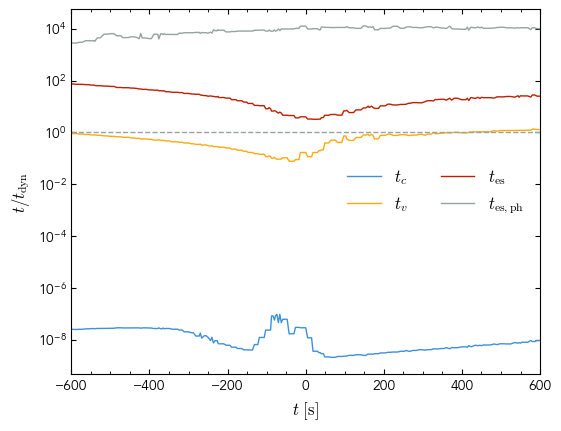

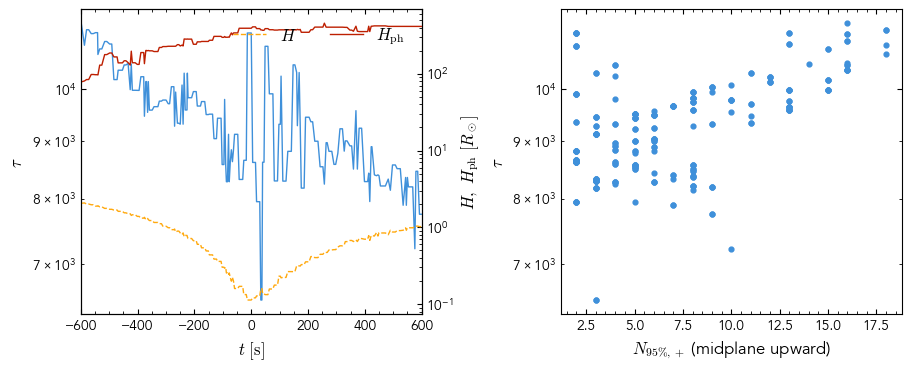

Single-cell column diagnostic: 1e5, snapshot 200
  cell, t<0: p=-0.716, R^2=0.988, N=134
  cell, t>0: p=-0.517, R^2=0.916, N=107
  column, t<0: p=-0.809, R^2=0.992, N=134
  column, t>0: p=-0.316, R^2=0.907, N=107


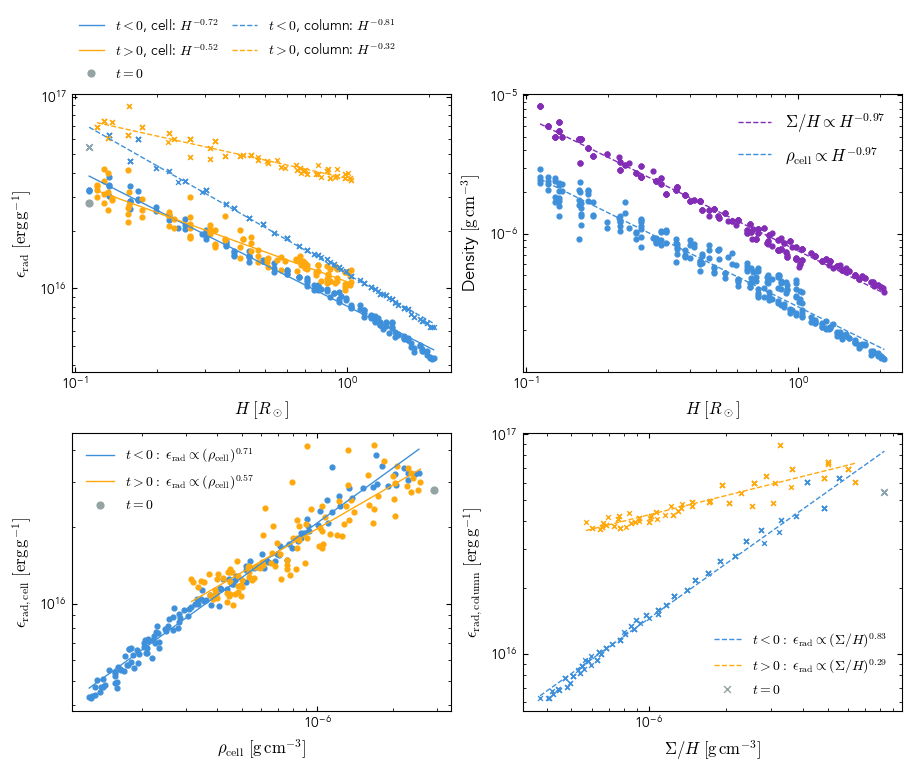

Streamline height: z range = -0.008257023649036424 Rsun to 0.04274307949123976 Rsun


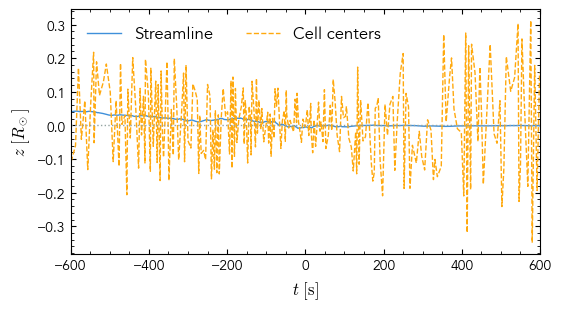

Single-cell specific energy ; integrated heating = 1.6678621647945992e+16 erg/g


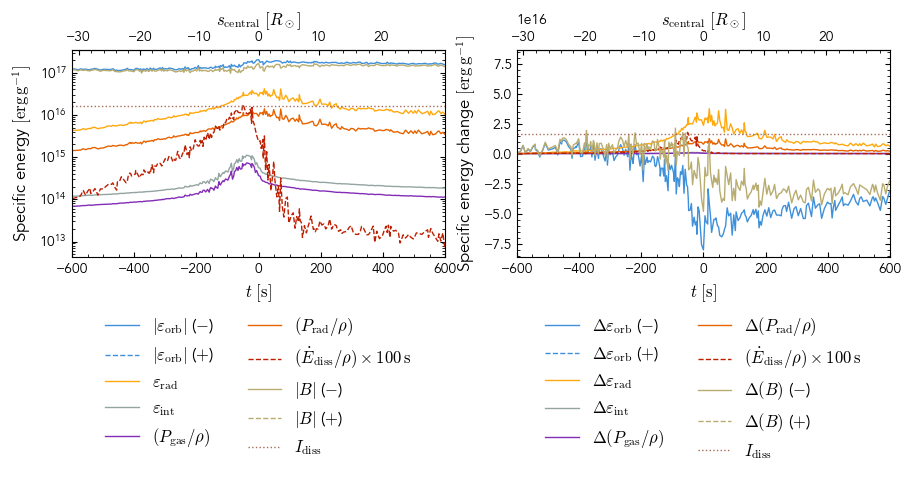

Initial cohort: 3040 unique native cells; radius = 82.99081131860575 Rsun ; rho > 2.915353099174869e-09 g/cm**3 ; centers within V^(1/3) of the plane; r dot r_seed > 0


Advected 3040 tracers; fixed initial mass = 1.6812198069448744e+27 g ; accepted midpoint substeps = 1920 ; displacement cap = 0.05 Rsun
Advected-cohort specific energy ; integrated heating = 2.6459358342125864e+16 erg/g


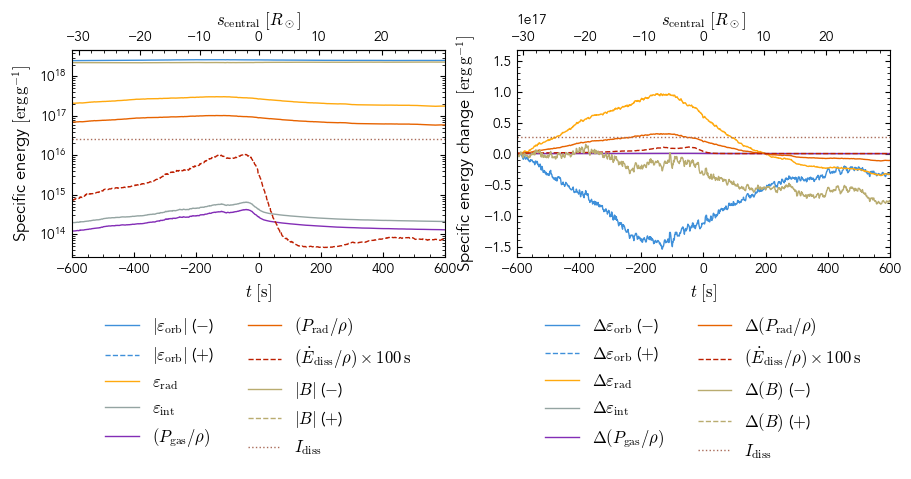

Launch flux mesh: 256 intervals per axis; 22531 retained patches, 23225 shared corners; radius = 82.99081131860575 Rsun ; retained transverse/vertical width ranges = [(unyt_quantity(0.03994744, 'Rsun'), unyt_quantity(1.06239968, 'Rsun')), (unyt_quantity(0.00316915, 'Rsun'), unyt_quantity(0.43070505, 'Rsun'))]


Advected flux surface: 22531 patches; 45756 corner/midpoint tracers; 1920 midpoint substeps; cap = 0.05 Rsun ; sampled 961 of 961 output times
Deformed-surface net Mdot: upstream = 2.7929991468957476 Msun/yr ; downstream = 2.8018539722402096 Msun/yr ; range = 2.6643600448182947 Msun/yr to 2.828491043146259 Msun/yr
Surface area range: 144.10240869316465 Rsun**2 to 1632.5959268974284 Rsun**2 ; maximum new-reversal share of absolute mass flux = 0.27%
Heating reference: integral(q v dot dA dt) / upstream net Mdot; signed lab-frame fluxes


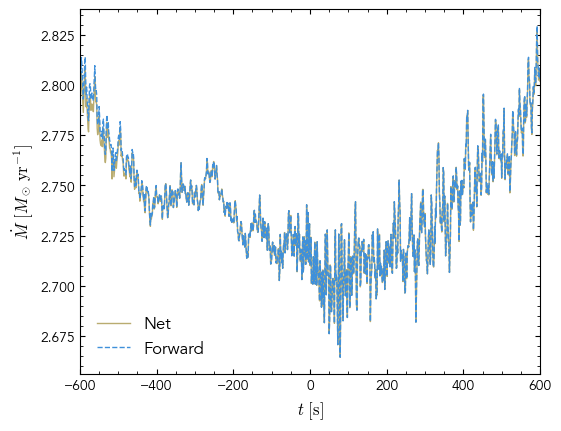

Snapshot 173, time = 5.890262161576989 day (0.701 t_fb)


Streamline seed cell: 28229003 at [ 2.58920714e+01 -8.91937442e+00 -1.19296671e-02] Rsun ; density = 1.8876279440393509e-07 g/cm**3 ; r_seed / r_p = 0.9899397729369024 dimensionless ; positive time follows the 3D velocity


Time grid: 961 points; limits = [-600.  600.] s ; spacing = 1.25 s
Central signed arc-distance limits: [-31.6822574  29.712478 ] Rsun
Central trajectory: 244 native-cell visits from 961 time samples; accepted midpoint substeps = 1920 ; positive time follows the 3D velocity


Projected time scales along the flow: nearest grid columns; max XY offset = 0.5414727318146412 Rsun


Photospheres: full snapshot z bounds = [-9827.3084802  10128.78715629] Rsun ; 97 unique XY columns; found 194 of 194 observer surfaces; search steps per ray = (np.int64(133), np.int64(205))
Mean photosphere height range = (unyt_quantity(0.76034392, 'Rsun'), unyt_quantity(66.72058203, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(549.53965907, 'dimensionless'), unyt_quantity(941.21310474, 'dimensionless')) ; native-nearest trapezoids, no density cut


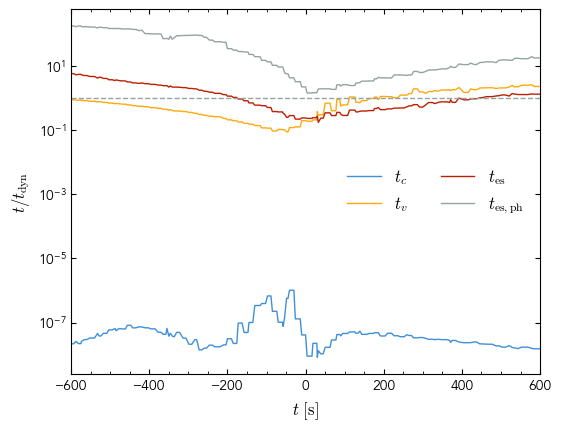

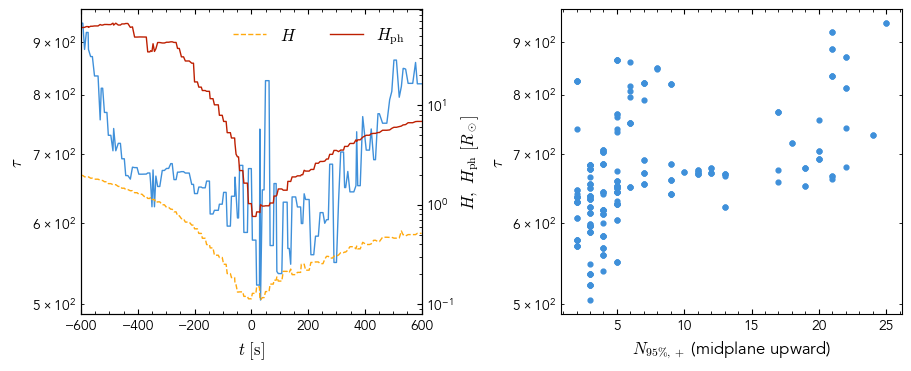

Single-cell column diagnostic: 1e5, snapshot 173
  cell, t<0: p=-0.776, R^2=0.973, N=123
  cell, t>0: p=-1.320, R^2=0.863, N=120
  column, t<0: p=-0.746, R^2=0.950, N=123
  column, t>0: p=-0.929, R^2=0.887, N=120


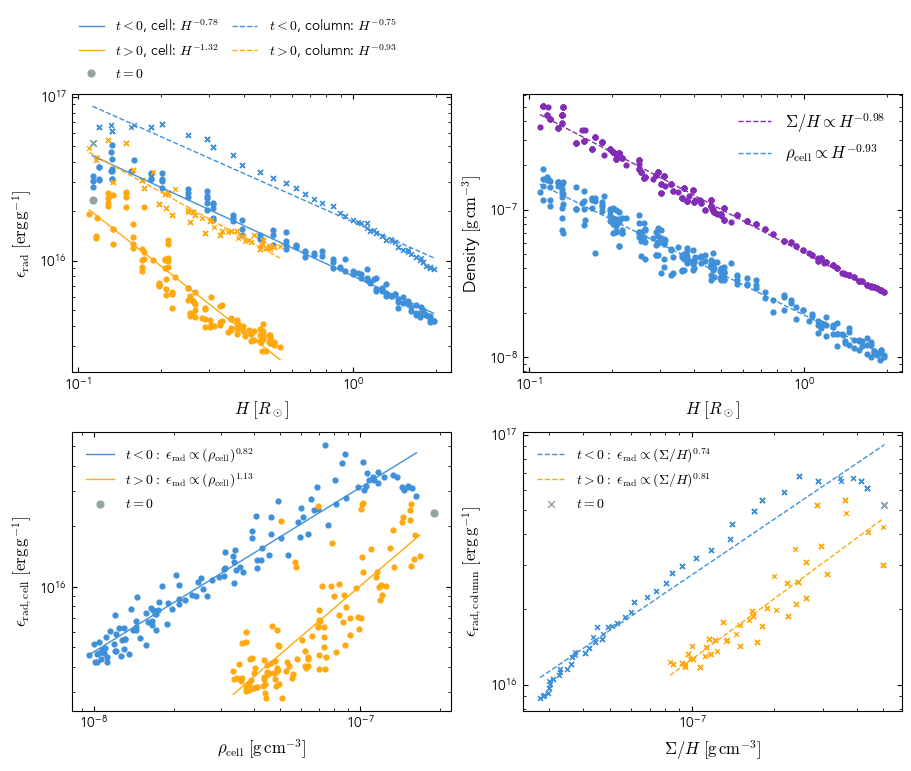

Streamline height: z range = -0.8510285045784365 Rsun to 0.0005942448549177522 Rsun


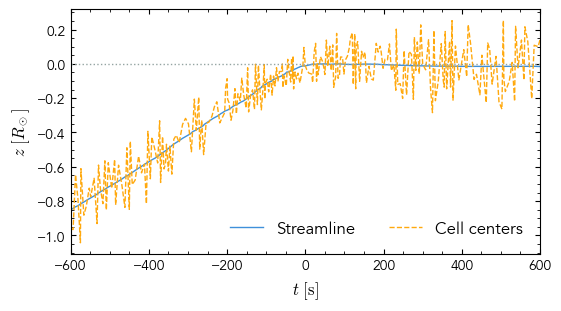

Single-cell specific energy ; integrated heating = 1.829485519598305e+16 erg/g


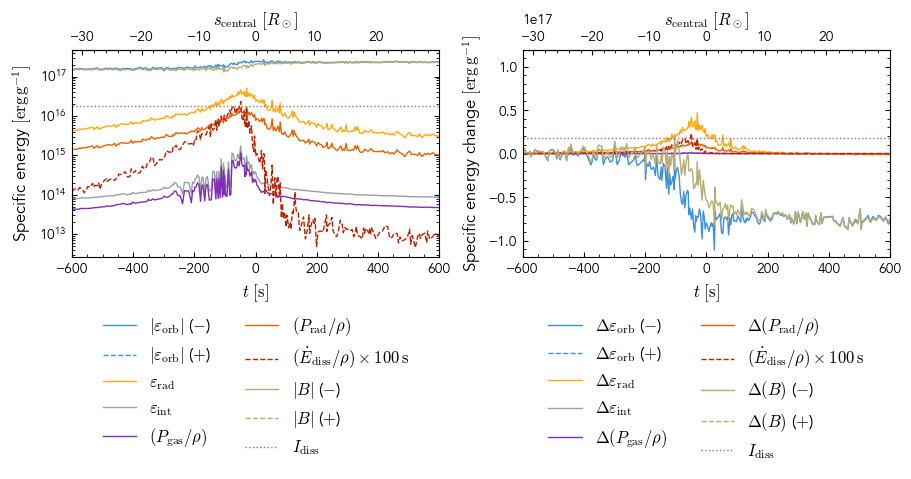

Initial cohort: 1686 unique native cells; radius = 82.99081131860575 Rsun ; rho > 1.887627944039351e-10 g/cm**3 ; centers within V^(1/3) of the plane; r dot r_seed > 0


Advected 1686 tracers; fixed initial mass = 1.5395153994330478e+26 g ; accepted midpoint substeps = 1920 ; displacement cap = 0.05 Rsun
Advected-cohort specific energy ; integrated heating = 1.3070761339883096e+17 erg/g


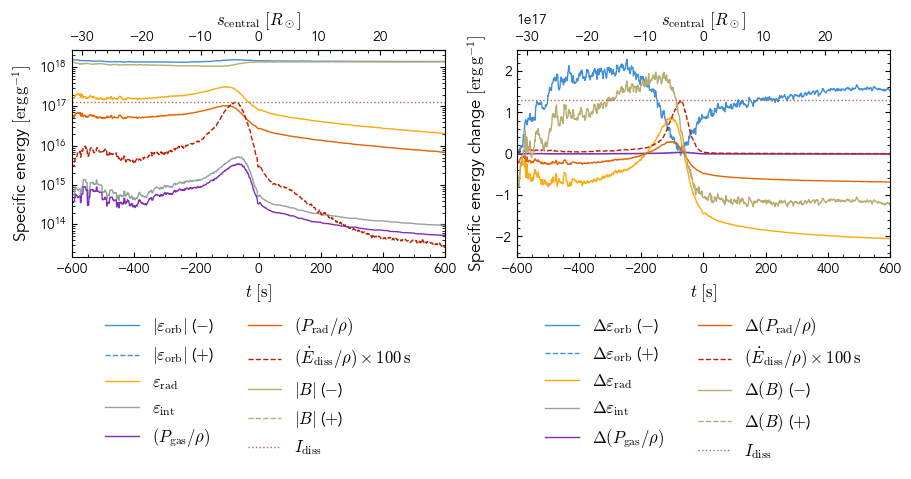

Launch flux mesh: 256 intervals per axis; 20003 retained patches, 20715 shared corners; radius = 82.99081131860575 Rsun ; retained transverse/vertical width ranges = [(unyt_quantity(0.03994744, 'Rsun'), unyt_quantity(1.58360514, 'Rsun')), (unyt_quantity(0.00316914, 'Rsun'), unyt_quantity(0.14673797, 'Rsun'))]


Advected flux surface: 20003 patches; 40718 corner/midpoint tracers; 1926 midpoint substeps; cap = 0.05 Rsun ; sampled 961 of 961 output times
Deformed-surface net Mdot: upstream = 0.2347864964680028 Msun/yr ; downstream = 0.30237578397747455 Msun/yr ; range = 0.2345437658425426 Msun/yr to 0.3097620895147063 Msun/yr
Surface area range: 78.52095174459623 Rsun**2 to 6298.715894921569 Rsun**2 ; maximum new-reversal share of absolute mass flux = 3.14%
Heating reference: integral(q v dot dA dt) / upstream net Mdot; signed lab-frame fluxes


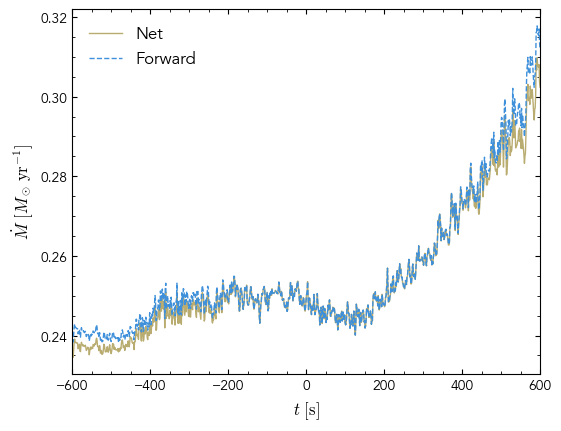

In [12]:
RUN = "1e5"
RSTAR, MSTAR, MBH = (
    0.47 * richio.units.lscale,
    0.5 * richio.units.mscale,
    1e5 * richio.units.mscale,
)
r_p = float((RSTAR * (MBH / MSTAR) ** (1 / 3)).in_units("code_length"))

XY = 100

TFBS = [0.7, 1.0]
SNAPSHOTS = dev.SNAPSHOT_TFB(RUN, TFBS)

t_dyn = np.sqrt(RSTAR**3 / (u.G * MSTAR))
t_fb = dev.TDEBasics(MBH, MSTAR, RSTAR).t_fb
print(
    "Run:",
    RUN,
    "\nStellar dynamical time:",
    t_dyn.in_units("s"),
    "\nFallback time:",
    t_fb.in_units("day"),
)

for SNAPDIR in list(reversed(SNAPSHOTS))[:SNAPSHOT_LIMIT]:
    snapnum = int(os.path.splitext(os.path.basename(SNAPDIR))[0].rsplit("_", 1)[1])
    snap = richio.load(SNAPDIR)
    time_in_tfb = np.asarray((snap.time / t_fb).to_value("dimensionless")).item()
    print(
        f"Snapshot {snapnum}, time = {snap.time.in_units('day')} "
        f"({time_in_tfb:.3f} t_fb)"
    )

    native = load_native_fields(snap)
    seed_cell = get_max_density_cell(native, r_p)
    tree = cKDTree(
        np.column_stack([axis.to_value("Rsun") for axis in native["position"]])
    )
    streamline = get_streamline(native, seed_cell, tree)

    # Calculate, plot, then release each diagnostic group before starting the next.
    columns = compute_column_profiles(snap, native, streamline, r_p, XY, tree)
    plot_timescales(streamline, columns, t_dyn)
    plot_optical_depth_diagnostics(streamline, columns)
    plot_height_scalings(streamline, columns, RUN, snapnum)
    del columns
    plot_streamline_height(streamline)

    energy_fields = compute_energy_fields(native, MBH, r_p)
    single = compute_single_cell_profiles(native, streamline, energy_fields)
    # plot_single_cell_energy_density(streamline, single)
    plot_single_cell_specific_energy(streamline, single)
    del single

    slices = compute_slice_profiles(
        native, streamline, energy_fields, r_p, seed_cell, tree
    )
    plot_slice_specific_energy(streamline, slices)
    # plot_slice_energy_density(streamline, slices)
    del slices

    flux = compute_mass_flux_profiles(
        native, streamline, energy_fields, r_p, seed_cell, tree
    )
    # plot_flux_specific_energy(streamline, flux)
    plot_mass_flux(streamline, flux)
    # check_flux_surface_resolution(
    #     native, streamline, energy_fields, r_p, seed_cell, tree, flux
    # )
    del flux, energy_fields, streamline, tree, native, snap

## $10^4$


Run: 1e4 
Stellar dynamical time: 730.4628659211085 s 
Fallback time: 2.656037932057755 day
Snapshot 151, time = [5.77629162] day (2.175 t_fb)


Streamline seed cell: 45467225 at [ 1.23072202e+01 -2.92261252e+00 -9.70176407e-03] Rsun ; density = 0.00026443568505437335 g/cm**3 ; r_seed / r_p = 0.9851386630838429 dimensionless ; positive time follows the 3D velocity


Time grid: 961 points; limits = [-600.  600.] s ; spacing = 1.25 s
Central signed arc-distance limits: [-14.62604768  13.79959912] Rsun
Central trajectory: 371 native-cell visits from 961 time samples; accepted midpoint substeps = 960 ; positive time follows the 3D velocity


Projected time scales along the flow: nearest grid columns; max XY offset = 0.1610887999590061 Rsun


Photospheres: full snapshot z bounds = [-18636.51624661  16107.06366542] Rsun ; 152 unique XY columns; found 304 of 304 observer surfaces; search steps per ray = (np.int64(121), np.int64(134))
Mean photosphere height range = (unyt_quantity(1706.28433407, 'Rsun'), unyt_quantity(1737.55229173, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(431175.08383732, 'dimensionless'), unyt_quantity(693480.88976929, 'dimensionless')) ; native-nearest trapezoids, no density cut


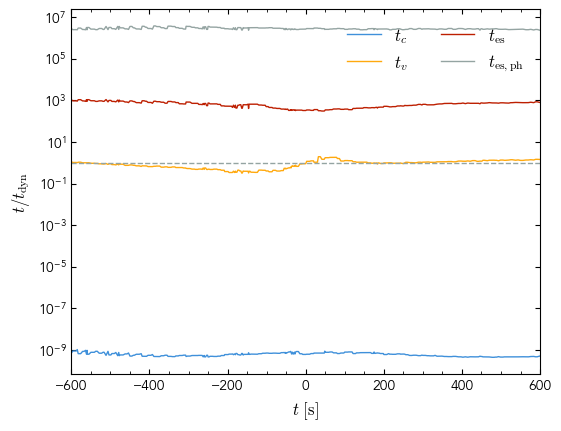

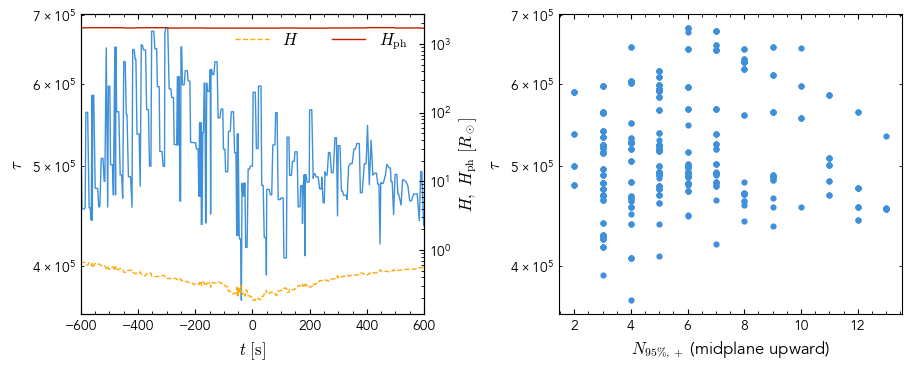

Single-cell column diagnostic: 1e4, snapshot 151
  cell, t<0: p=-2.520, R^2=0.780, N=212
  cell, t>0: p=-0.859, R^2=0.876, N=158
  column, t<0: p=-1.241, R^2=0.863, N=212
  column, t>0: p=-0.416, R^2=0.569, N=158


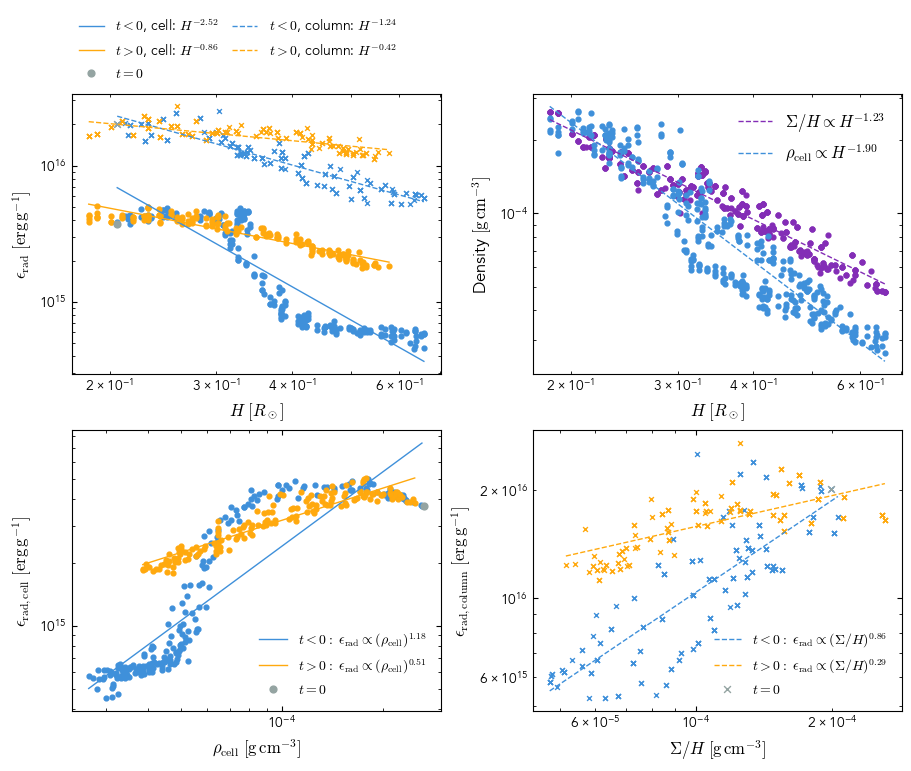

Streamline height: z range = -0.07973248246097653 Rsun to 0.0514260557977251 Rsun


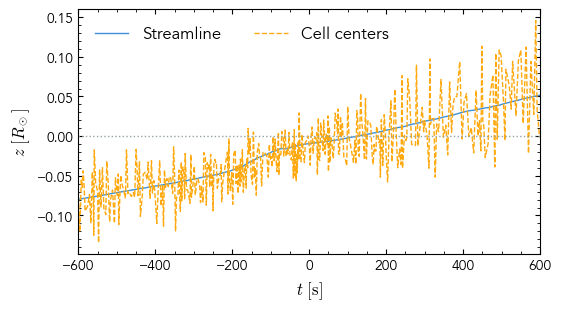

Single-cell specific energy ; integrated heating = 1152806307852764.8 erg/g


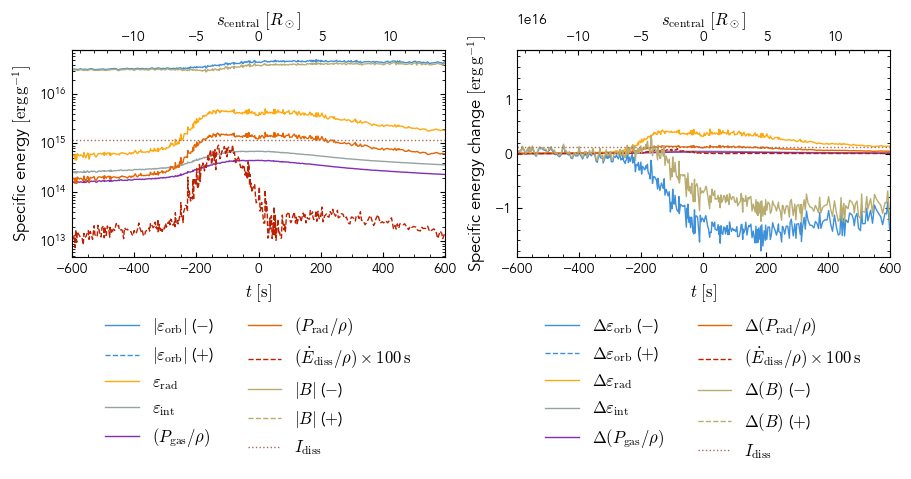

Initial cohort: 3612 unique native cells; radius = 38.52092231089054 Rsun ; rho > 2.6443568505437334e-07 g/cm**3 ; centers within V^(1/3) of the plane; r dot r_seed > 0


Advected 3612 tracers; fixed initial mass = 6.145224430392034e+27 g ; accepted midpoint substeps = 960 ; displacement cap = 0.05 Rsun
Advected-cohort specific energy ; integrated heating = 9290613004883676.0 erg/g


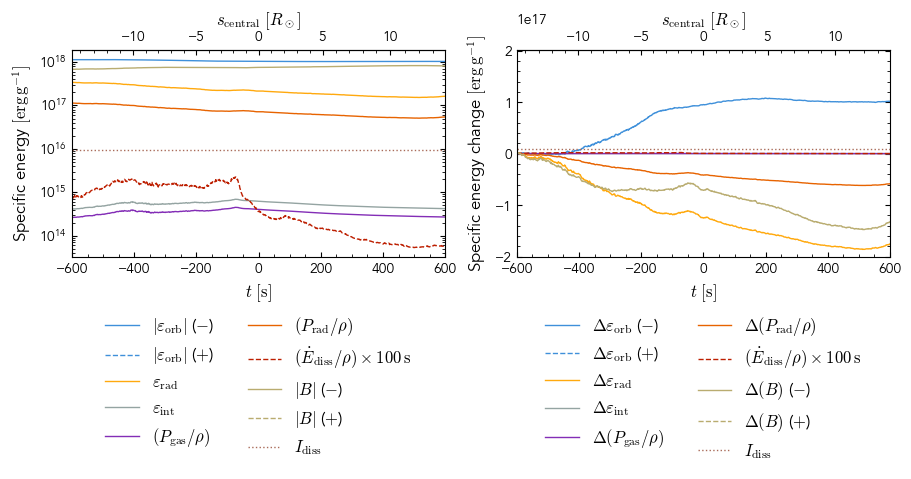

Launch flux mesh: 256 intervals per axis; 15301 retained patches, 15988 shared corners; radius = 38.52092231089054 Rsun ; retained transverse/vertical width ranges = [(unyt_quantity(0.03394806, 'Rsun'), unyt_quantity(0.42016671, 'Rsun')), (unyt_quantity(0.00286877, 'Rsun'), unyt_quantity(0.17215689, 'Rsun'))]


Advected flux surface: 15301 patches; 31289 corner/midpoint tracers; 960 midpoint substeps; cap = 0.05 Rsun ; sampled 961 of 961 output times
Deformed-surface net Mdot: upstream = 12.47434232166151 Msun/yr ; downstream = 11.874858428339992 Msun/yr ; range = 11.664342398705182 Msun/yr to 12.507123410752518 Msun/yr
Surface area range: 24.141211681662938 Rsun**2 to 1043.2366701551216 Rsun**2 ; maximum new-reversal share of absolute mass flux = 2.91%
Heating reference: integral(q v dot dA dt) / upstream net Mdot; signed lab-frame fluxes


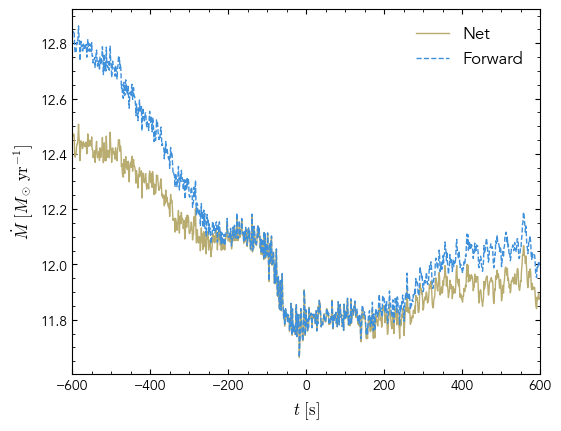

Snapshot 108, time = [3.96398148] day (1.492 t_fb)


Streamline seed cell: 34963870 at [ 1.15882792e+01 -3.32631488e+00  6.67555505e-04] Rsun ; density = 0.000261305904144604 g/cm**3 ; r_seed / r_p = 0.9389359298506142 dimensionless ; positive time follows the 3D velocity


Time grid: 961 points; limits = [-600.  600.] s ; spacing = 1.25 s
Central signed arc-distance limits: [-14.98090865  13.99087334] Rsun
Central trajectory: 352 native-cell visits from 961 time samples; accepted midpoint substeps = 960 ; positive time follows the 3D velocity


Projected time scales along the flow: nearest grid columns; max XY offset = 0.1525843539828382 Rsun


Photospheres: full snapshot z bounds = [-8290.84467883  7424.00634756] Rsun ; 159 unique XY columns; found 318 of 318 observer surfaces; search steps per ray = (np.int64(164), np.int64(206))
Mean photosphere height range = (unyt_quantity(234.76086981, 'Rsun'), unyt_quantity(274.49017041, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(558269.27408749, 'dimensionless'), unyt_quantity(2250212.73351551, 'dimensionless')) ; native-nearest trapezoids, no density cut


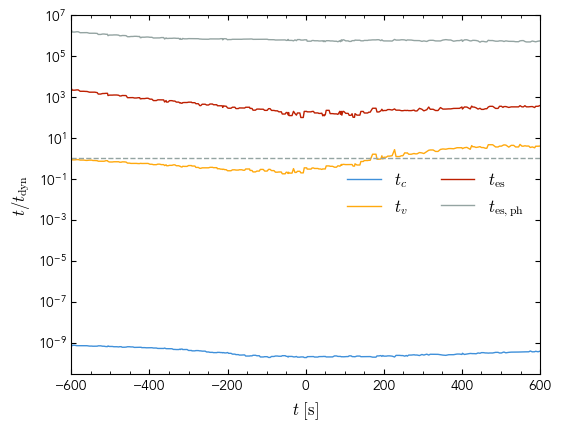

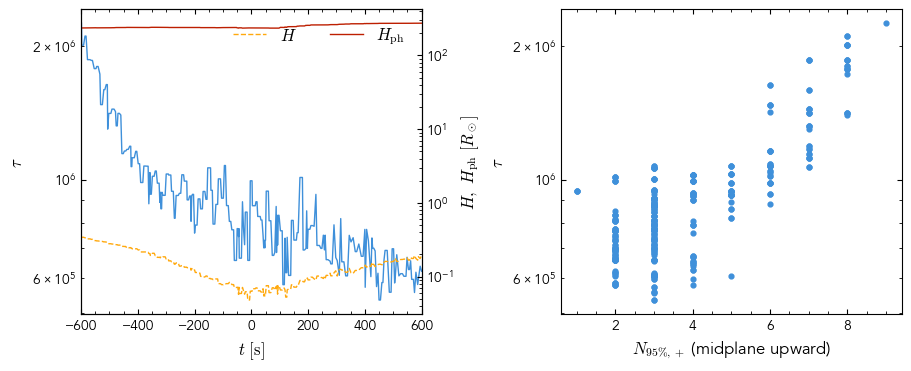

Single-cell column diagnostic: 1e4, snapshot 108
  cell, t<0: p=-1.504, R^2=0.983, N=202
  cell, t>0: p=-0.466, R^2=0.792, N=149
  column, t<0: p=-1.855, R^2=0.977, N=202
  column, t>0: p=-0.127, R^2=0.181, N=149


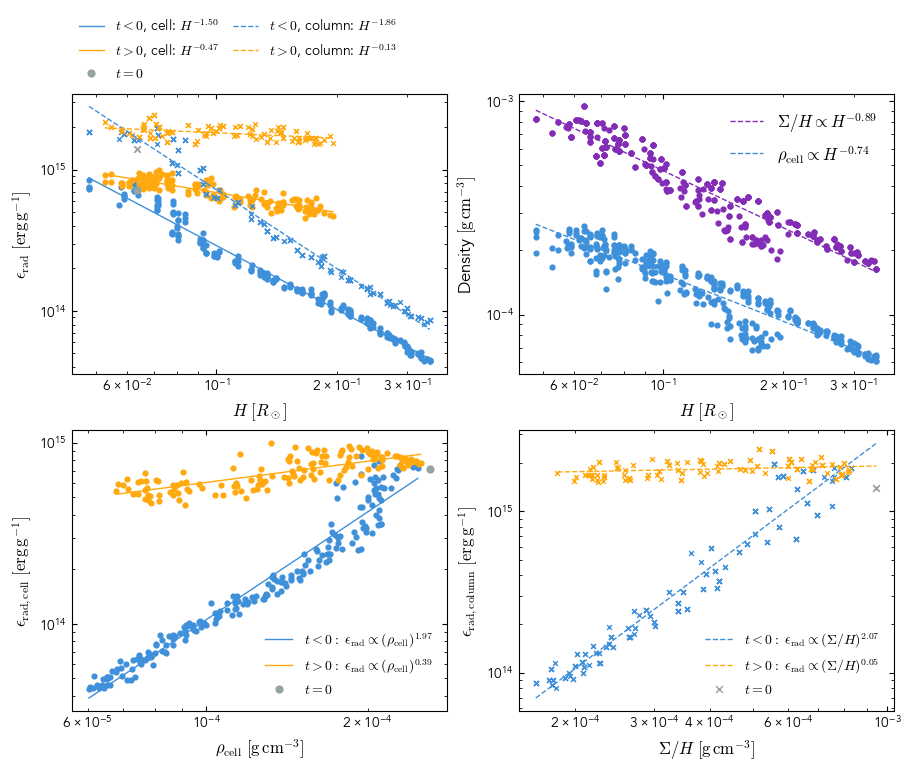

Streamline height: z range = -0.0021461972700483768 Rsun to 0.029409990559704658 Rsun


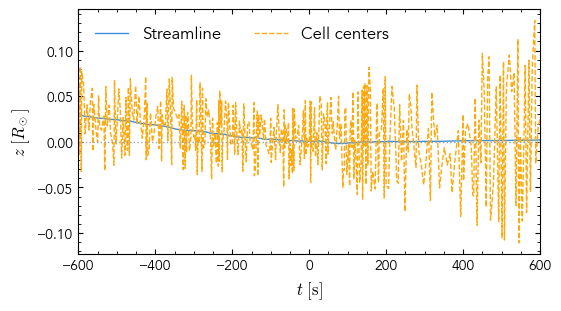

Single-cell specific energy ; integrated heating = 459738668858062.0 erg/g


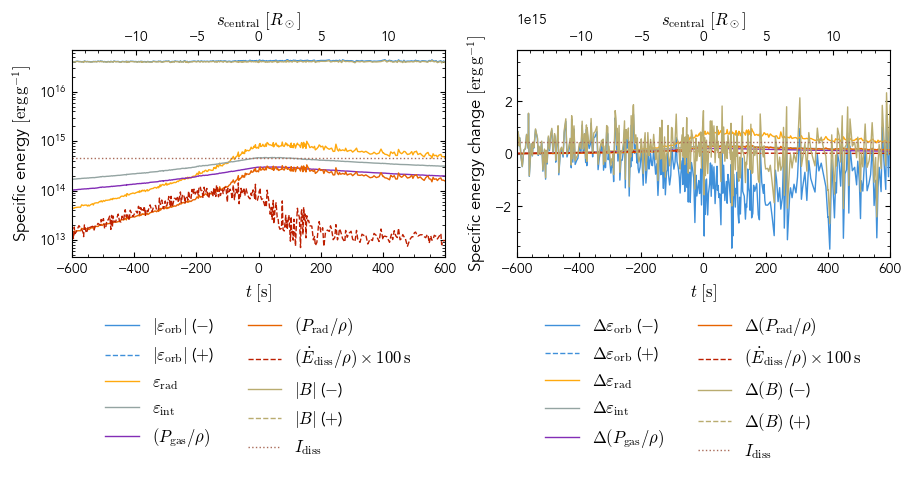

Initial cohort: 1758 unique native cells; radius = 38.52092231089054 Rsun ; rho > 2.61305904144604e-07 g/cm**3 ; centers within V^(1/3) of the plane; r dot r_seed > 0


Advected 1758 tracers; fixed initial mass = 5.708499248454715e+27 g ; accepted midpoint substeps = 960 ; displacement cap = 0.05 Rsun
Advected-cohort specific energy ; integrated heating = 3810508122768390.0 erg/g


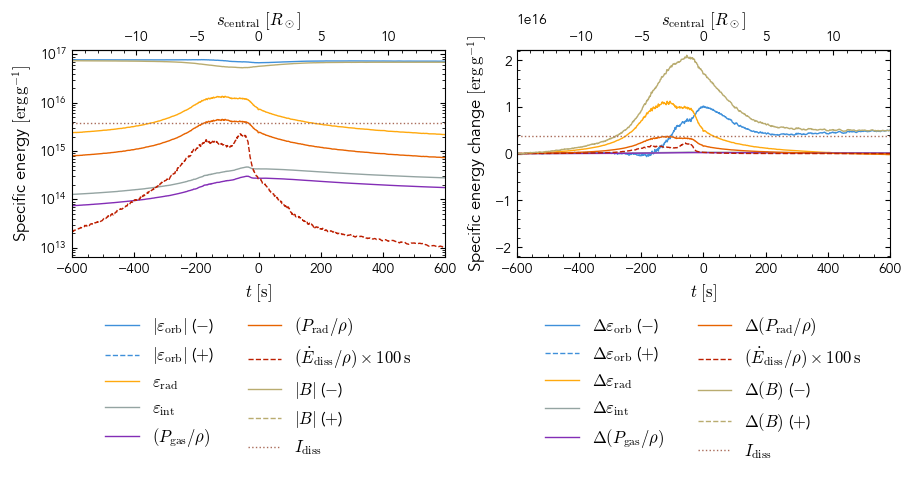

Launch flux mesh: 256 intervals per axis; 14018 retained patches, 14641 shared corners; radius = 38.52092231089054 Rsun ; retained transverse/vertical width ranges = [(unyt_quantity(0.03394806, 'Rsun'), unyt_quantity(0.280173, 'Rsun')), (unyt_quantity(0.00286879, 'Rsun'), unyt_quantity(0.03882323, 'Rsun'))]


Advected flux surface: 14018 patches; 28659 corner/midpoint tracers; 960 midpoint substeps; cap = 0.05 Rsun ; sampled 961 of 961 output times
Deformed-surface net Mdot: upstream = 13.406165754612774 Msun/yr ; downstream = 12.338439577096052 Msun/yr ; range = 12.317419537343596 Msun/yr to 13.45137897308715 Msun/yr
Surface area range: 8.13425730181243 Rsun**2 to 246.58437849332694 Rsun**2 ; maximum new-reversal share of absolute mass flux = 0.33%
Heating reference: integral(q v dot dA dt) / upstream net Mdot; signed lab-frame fluxes


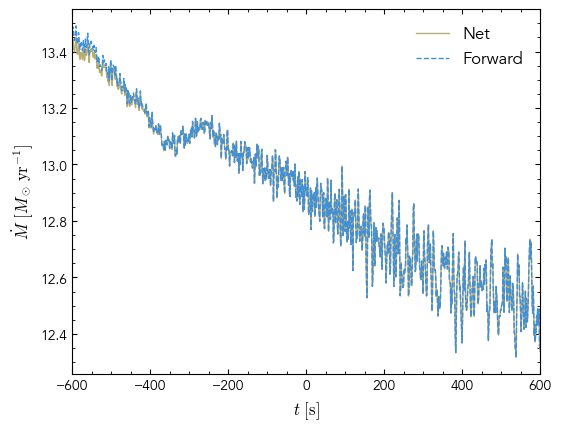

Snapshot 77, time = [2.65338265] day (0.999 t_fb)


Streamline seed cell: 21640730 at [ 1.14450763e+01 -4.89275355e+00  4.36986917e-03] Rsun ; density = 0.00015594935750312919 g/cm**3 ; r_seed / r_p = 0.9693725000079253 dimensionless ; positive time follows the 3D velocity


Time grid: 961 points; limits = [-600.  600.] s ; spacing = 1.25 s
Central signed arc-distance limits: [-14.90897972  13.65091677] Rsun
Central trajectory: 335 native-cell visits from 961 time samples; accepted midpoint substeps = 960 ; positive time follows the 3D velocity


Projected time scales along the flow: nearest grid columns; max XY offset = 0.1596776505288652 Rsun


Photospheres: full snapshot z bounds = [-3537.06607603  3070.91925725] Rsun ; 158 unique XY columns; found 316 of 316 observer surfaces; search steps per ray = (np.int64(258), np.int64(450))
Mean photosphere height range = (unyt_quantity(4.29662707, 'Rsun'), unyt_quantity(34.09640779, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(345211.49132494, 'dimensionless'), unyt_quantity(1748230.52256607, 'dimensionless')) ; native-nearest trapezoids, no density cut


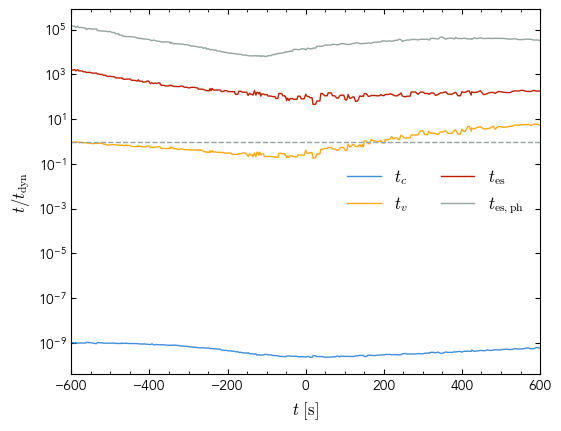

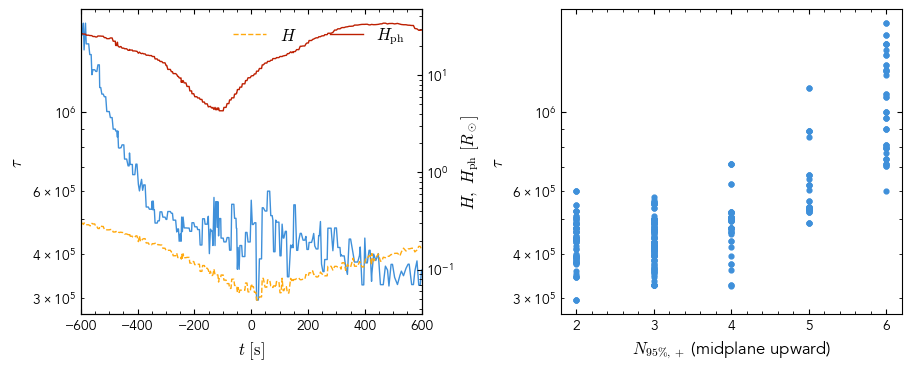

Single-cell column diagnostic: 1e4, snapshot 77
  cell, t<0: p=-2.111, R^2=0.981, N=201
  cell, t>0: p=-0.462, R^2=0.639, N=133
  column, t<0: p=-1.653, R^2=0.983, N=201
  column, t>0: p=-0.160, R^2=0.238, N=133


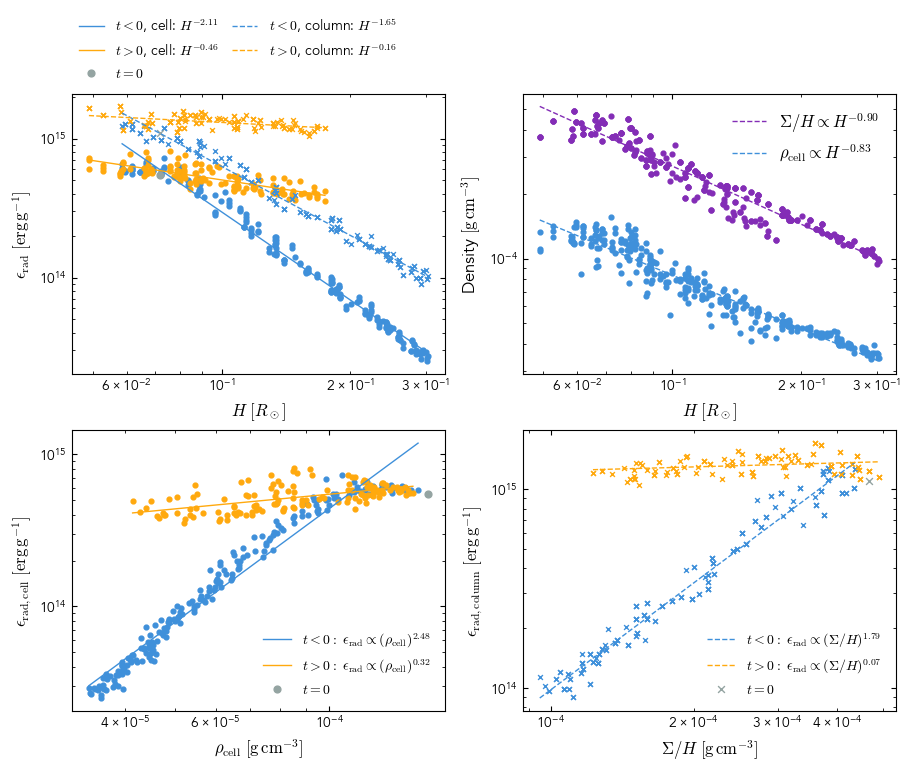

Streamline height: z range = 0.0019615358339263138 Rsun to 0.042451486517185735 Rsun


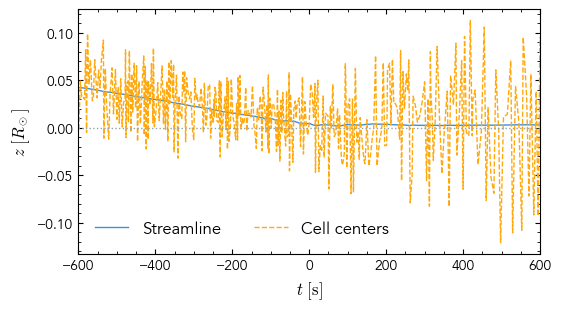

Single-cell specific energy ; integrated heating = 398150476611823.8 erg/g


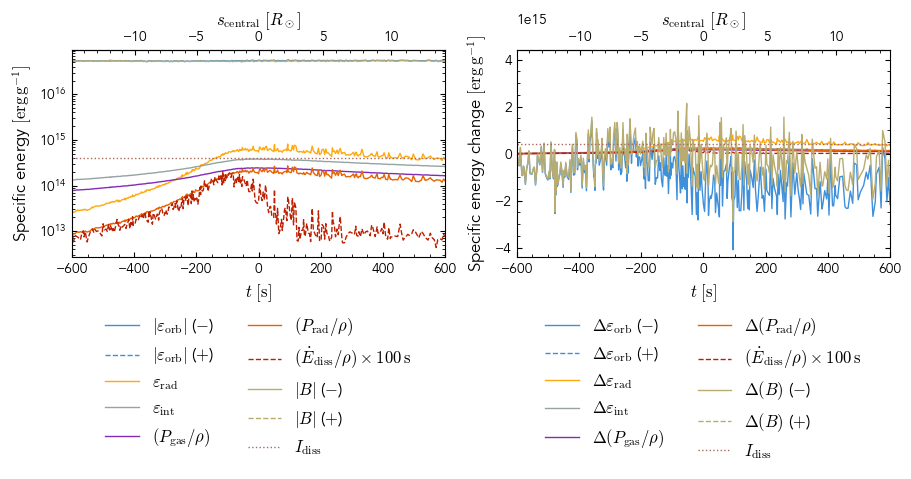

Initial cohort: 894 unique native cells; radius = 38.52092231089054 Rsun ; rho > 1.559493575031292e-07 g/cm**3 ; centers within V^(1/3) of the plane; r dot r_seed > 0


Advected 894 tracers; fixed initial mass = 2.753481379100208e+27 g ; accepted midpoint substeps = 960 ; displacement cap = 0.05 Rsun
Advected-cohort specific energy ; integrated heating = 4077398222187675.0 erg/g


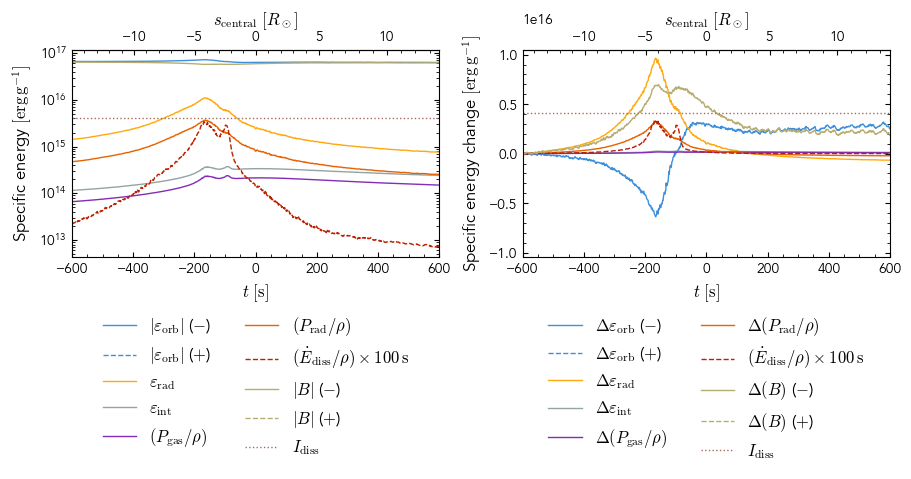

Launch flux mesh: 256 intervals per axis; 12270 retained patches, 12837 shared corners; radius = 38.52092231089054 Rsun ; retained transverse/vertical width ranges = [(unyt_quantity(0.03394806, 'Rsun'), unyt_quantity(0.24488517, 'Rsun')), (unyt_quantity(0.00286878, 'Rsun'), unyt_quantity(0.03089306, 'Rsun'))]


Advected flux surface: 12270 patches; 25107 corner/midpoint tracers; 960 midpoint substeps; cap = 0.05 Rsun ; sampled 961 of 961 output times
Deformed-surface net Mdot: upstream = 5.96759520592645 Msun/yr ; downstream = 5.446103212038599 Msun/yr ; range = 5.383919383336692 Msun/yr to 5.981409275996862 Msun/yr
Surface area range: 5.776640680779002 Rsun**2 to 330.2144394637679 Rsun**2 ; maximum new-reversal share of absolute mass flux = 0.02%
Heating reference: integral(q v dot dA dt) / upstream net Mdot; signed lab-frame fluxes


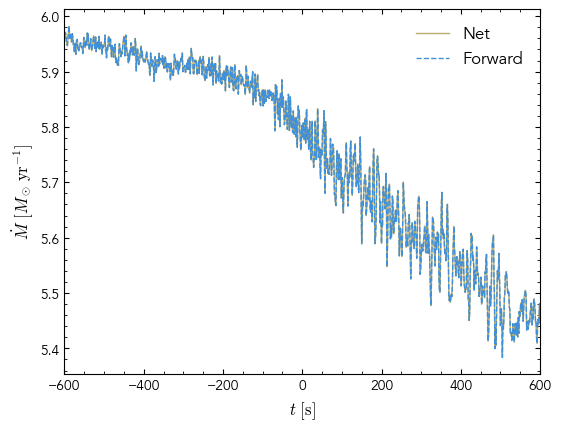

Snapshot 62, time = [1.86088432] day (0.701 t_fb)


Streamline seed cell: 40481769 at [ 1.19412606e+01 -3.47065047e+00  1.05657472e-02] Rsun ; density = 2.438843796092837e-05 g/cm**3 ; r_seed / r_p = 0.968466087307658 dimensionless ; positive time follows the 3D velocity


Time grid: 961 points; limits = [-600.  600.] s ; spacing = 1.25 s
Central signed arc-distance limits: [-14.57869655  13.75275093] Rsun
Central trajectory: 317 native-cell visits from 961 time samples; accepted midpoint substeps = 960 ; positive time follows the 3D velocity


Projected time scales along the flow: nearest grid columns; max XY offset = 0.1559710979324437 Rsun


Photospheres: full snapshot z bounds = [-1916.7182177   2209.48716538] Rsun ; 154 unique XY columns; found 308 of 308 observer surfaces; search steps per ray = (np.int64(142), np.int64(400))
Mean photosphere height range = (unyt_quantity(0.45859549, 'Rsun'), unyt_quantity(20.02987033, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(41277.8218426, 'dimensionless'), unyt_quantity(204286.23459359, 'dimensionless')) ; native-nearest trapezoids, no density cut


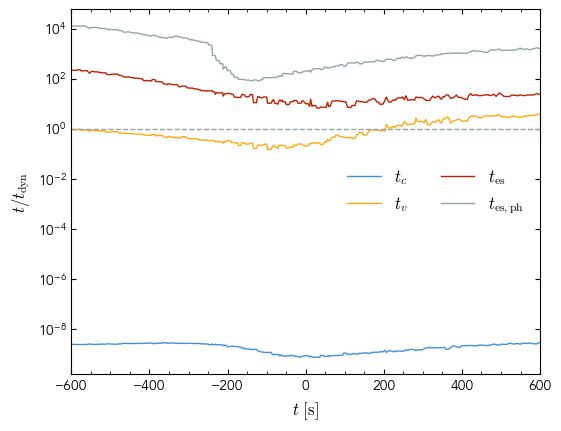

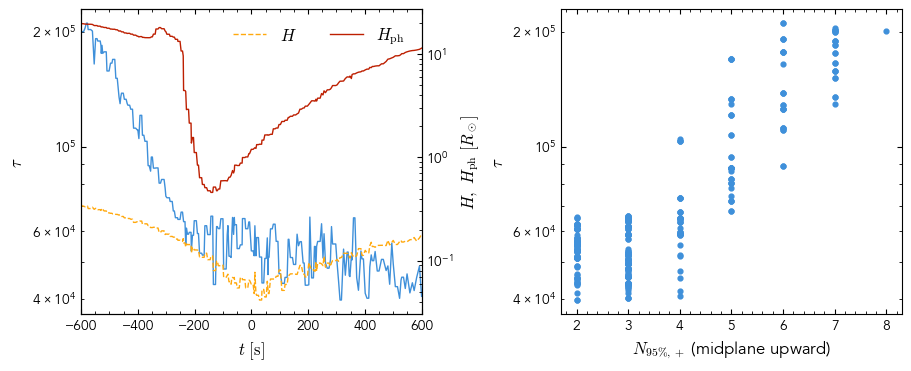

Single-cell column diagnostic: 1e4, snapshot 62
  cell, t<0: p=-1.699, R^2=0.977, N=185
  cell, t>0: p=-0.585, R^2=0.771, N=131
  column, t<0: p=-1.358, R^2=0.974, N=185
  column, t>0: p=-0.292, R^2=0.546, N=131


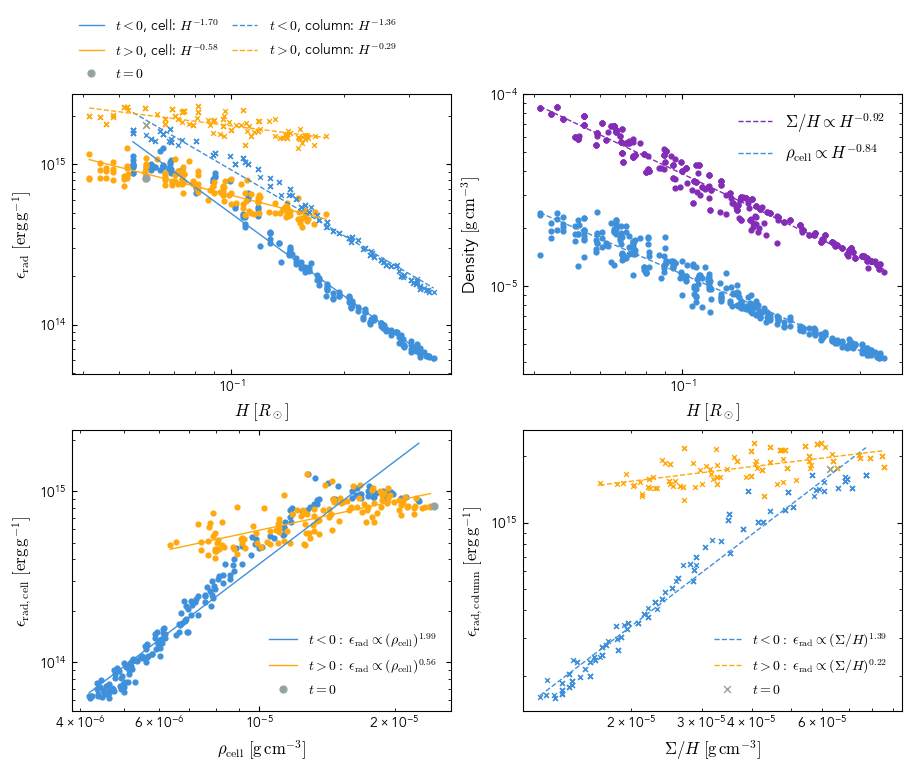

Streamline height: z range = 0.005609795170871213 Rsun to 0.05645999788243089 Rsun


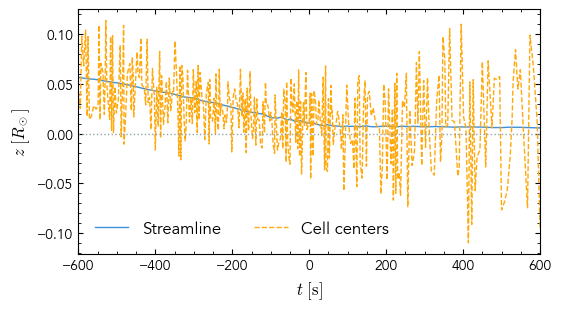

Single-cell specific energy ; integrated heating = 538951458256556.6 erg/g


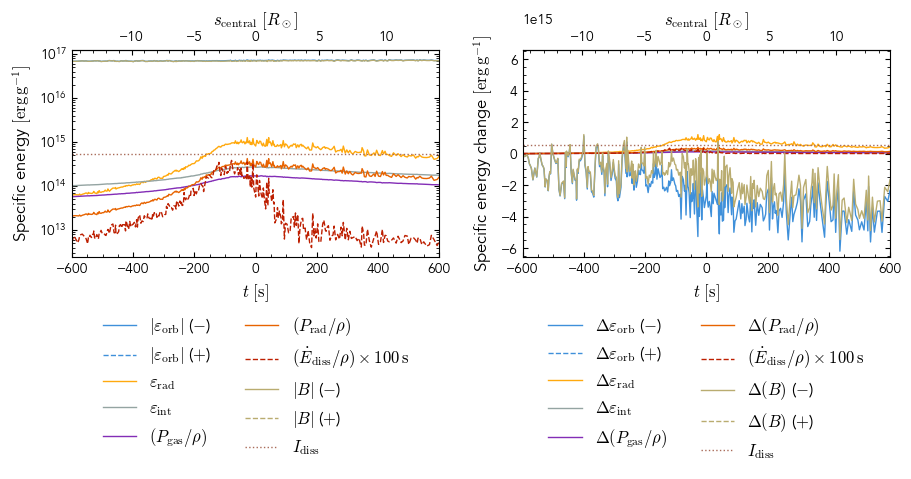

Initial cohort: 1053 unique native cells; radius = 38.52092231089054 Rsun ; rho > 2.4388437960928372e-08 g/cm**3 ; centers within V^(1/3) of the plane; r dot r_seed > 0


Advected 1053 tracers; fixed initial mass = 4.747169841004679e+26 g ; accepted midpoint substeps = 960 ; displacement cap = 0.05 Rsun
Advected-cohort specific energy ; integrated heating = 1.3867670379093356e+16 erg/g


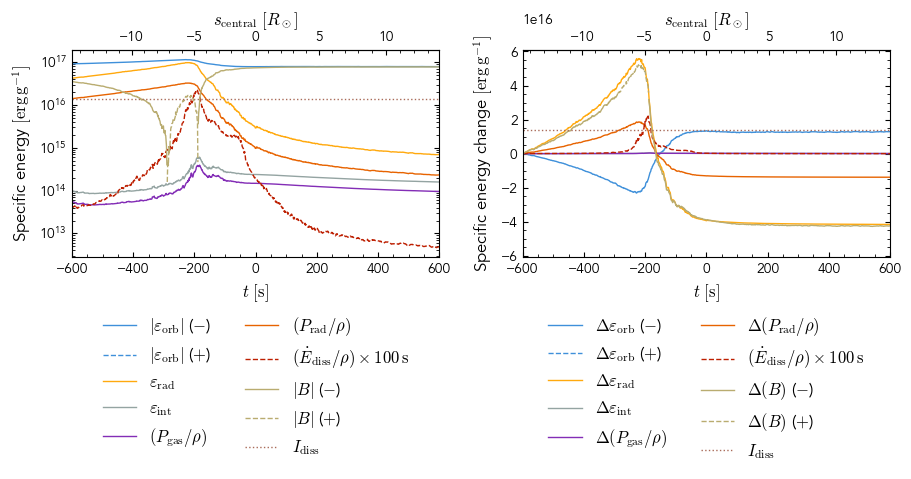

Launch flux mesh: 256 intervals per axis; 12580 retained patches, 13259 shared corners; radius = 38.52092231089054 Rsun ; retained transverse/vertical width ranges = [(unyt_quantity(0.03394806, 'Rsun'), unyt_quantity(0.32063304, 'Rsun')), (unyt_quantity(0.00286877, 'Rsun'), unyt_quantity(0.02756534, 'Rsun'))]


Advected flux surface: 12580 patches; 25839 corner/midpoint tracers; 960 midpoint substeps; cap = 0.05 Rsun ; sampled 961 of 961 output times
Deformed-surface net Mdot: upstream = 0.9959092755059828 Msun/yr ; downstream = 0.9083725041703323 Msun/yr ; range = 0.8993034918229817 Msun/yr to 0.9985258693362717 Msun/yr
Surface area range: 5.932882088213386 Rsun**2 to 1208.299416479792 Rsun**2 ; maximum new-reversal share of absolute mass flux = 0.11%
Heating reference: integral(q v dot dA dt) / upstream net Mdot; signed lab-frame fluxes


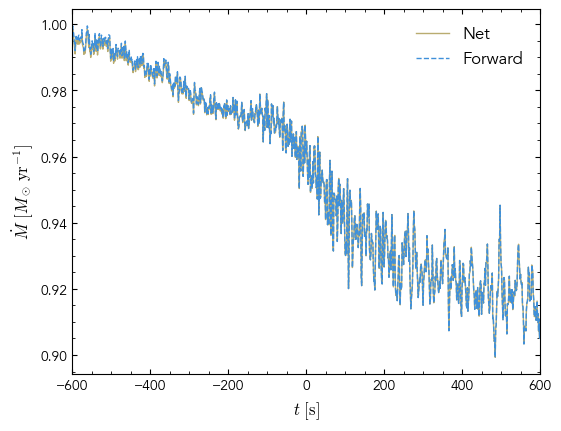

In [13]:
RUN = "1e4"
RSTAR, MSTAR, MBH = (
    0.47 * richio.units.lscale,
    0.5 * richio.units.mscale,
    1e4 * richio.units.mscale,
)
r_p = float((RSTAR * (MBH / MSTAR) ** (1 / 3)).in_units("code_length"))

XY = 30

TFBS = [0.7, 1.0, 1.5, 2.2]
SNAPSHOTS = dev.SNAPSHOT_TFB(RUN, TFBS)

t_dyn = np.sqrt(RSTAR**3 / (u.G * MSTAR))
t_fb = dev.TDEBasics(MBH, MSTAR, RSTAR).t_fb
print(
    "Run:",
    RUN,
    "\nStellar dynamical time:",
    t_dyn.in_units("s"),
    "\nFallback time:",
    t_fb.in_units("day"),
)

for SNAPDIR in list(reversed(SNAPSHOTS))[:SNAPSHOT_LIMIT]:
    snapnum = int(os.path.splitext(os.path.basename(SNAPDIR))[0].rsplit("_", 1)[1])
    snap = richio.load(SNAPDIR)
    time_in_tfb = np.asarray((snap.time / t_fb).to_value("dimensionless")).item()
    print(
        f"Snapshot {snapnum}, time = {snap.time.in_units('day')} "
        f"({time_in_tfb:.3f} t_fb)"
    )

    native = load_native_fields(snap)
    seed_cell = get_max_density_cell(native, r_p)
    tree = cKDTree(
        np.column_stack([axis.to_value("Rsun") for axis in native["position"]])
    )
    streamline = get_streamline(native, seed_cell, tree)

    # Calculate, plot, then release each diagnostic group before starting the next.
    columns = compute_column_profiles(snap, native, streamline, r_p, XY, tree)
    plot_timescales(streamline, columns, t_dyn)
    plot_optical_depth_diagnostics(streamline, columns)
    plot_height_scalings(streamline, columns, RUN, snapnum)
    del columns
    plot_streamline_height(streamline)

    energy_fields = compute_energy_fields(native, MBH, r_p)
    single = compute_single_cell_profiles(native, streamline, energy_fields)
    # plot_single_cell_energy_density(streamline, single)
    plot_single_cell_specific_energy(streamline, single)
    del single

    slices = compute_slice_profiles(
        native, streamline, energy_fields, r_p, seed_cell, tree
    )
    plot_slice_specific_energy(streamline, slices)
    # plot_slice_energy_density(streamline, slices)
    del slices

    flux = compute_mass_flux_profiles(
        native, streamline, energy_fields, r_p, seed_cell, tree
    )
    # plot_flux_specific_energy(streamline, flux)
    plot_mass_flux(streamline, flux)
    # check_flux_surface_resolution(
    #     native, streamline, energy_fields, r_p, seed_cell, tree, flux
    # )
    del flux, energy_fields, streamline, tree, native, snap